
# Pixel-level emersion and exposure time rasters

This notebook calculates high-resolution emersion and exposure-time rasters for:

- **May 4, 2026**
- **May 18, 2026**

The elevation raster defines the output grid. The coarser imagery-acquisition-time rasters are aligned to that grid using nearest-neighbour resampling.

For each valid elevation/acquisition pixel:

1. Interpolate the processed chart-datum tide series.
2. Determine the relevant falling-tide crossing of the pixel elevation.
3. Calculate exposure duration as:

\[
	ext{exposure hours} = \max(0,\ 	ext{acquisition hour} - 	ext{emersion hour})
\]

Pixels still submerged at acquisition are assigned **0 exposure hours**.

The notebook writes, for each date:

- acquisition time aligned to the elevation grid;
- emersion time as decimal local hours relative to midnight on the target date;
- exposure duration in decimal hours;
- summary statistics and common-valid-pixel histograms for elevation, emersion time, acquisition time, and exposure duration.

> **Important:** The processed tide CSV is reused directly. Tide datetime and chart-datum level columns are auto-detected, but explicit override parameters are provided.


## Setup

In [14]:

%load_ext autoreload
%autoreload 2

import os
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.shutil import copy as rio_copy
from rasterio.vrt import WarpedVRT

import config
import hatfield_funcs as hf
import hatfield_funcs.helpers as hfh

plt.style.use("default")
%config InlineBackend.figure_format = "retina"

project_root = Path("../..").resolve()
sys.path.insert(0, str(project_root / "src"))


from biofilm_data.io import (
    load_full_station_dataset,
)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:

if os.getenv("GA_STORAGE_ACCOUNT_NAME") is None:
    raise RuntimeError(
        "This notebook is configured for Azure cloud storage. "
        "Set GA_STORAGE_ACCOUNT_NAME before running it."
    )

hf.config.configure_azure()
hf.config.configure_data_root_path(config.CONTAINER_NAME)

# Required for reliable GDAL random access and COG writing to Azure.
os.environ.setdefault("CPL_VSIL_USE_TEMP_FILE_FOR_RANDOM_WRITE", "YES")
os.environ.setdefault("IGNORE_COG_LAYOUT_BREAK", "YES")
os.environ.setdefault("GDAL_CACHEMAX", "512")


'512'

## Parameters

In [3]:

# Input data: paths are relative to the configured Azure container.
path_processed_tide_data = config.CONTAINER_FILE_PATHS["processed_tide_data_csv"]

path_elevation_raster_chart_datum = (
    "data/raw_clean/bathymetry/brunswick_bathymetry_clipped_cd.tif"
)

input_cases = {
    "may4": {
        "date": pd.Timestamp("2026-05-04"),
        "acquisition_path": (
            "data/raw_clean/imagery_contextual/interp_time_may4_10m.tif"
        ),
    },
    "may18": {
        "date": pd.Timestamp("2026-05-18"),
        "acquisition_path": (
            "data/raw_clean/imagery_contextual/interp_time_may18_10m.tif"
        ),
    },
}

# Tide-data selection.
SITE_VALUE = "brunswick"

# Set these explicitly if auto-detection does not select the intended columns.
TIDE_DATETIME_COLUMN = None
TIDE_LEVEL_COLUMN = None
TIDE_SITE_COLUMN = None

# The processed tide timestamps are assumed to already represent local wall-clock
# time. If they are timezone-aware, optionally set the intended local timezone,
# for example "America/Vancouver".
LOCAL_TIMEZONE = None

# Tide interpolation and crossing detection.
TIDE_INTERPOLATION_FREQUENCY = "1min"
TIDE_SEARCH_HOURS_BEFORE = 18
TIDE_SEARCH_HOURS_AFTER = 18
TIDE_MAX_INTERPOLATION_GAP = "3h"
TIDE_SMOOTHING_WINDOW = 5  # samples on the interpolated tide curve

# For a pixel submerged at acquisition, exposure is zero. For the emersion raster,
# use the next falling-tide crossing when one exists. Change this to "nodata" if
# submerged pixels should have no emersion-hour value.
SUBMERGED_EMERSION_MODE = "next_falling_crossing"  # or "nodata"

OUTPUT_NODATA = -9999.0
OUTPUT_DTYPE = "float32"
BLOCK_SIZE = 512
HISTOGRAM_BINS = 60
FORCE_REDO = False

output_directory = "data/processed/imagery_contextual"

for case_name, case in input_cases.items():
    date_label = case["date"].strftime("%Y%m%d")
    case["aligned_acquisition_output"] = (
        f"{output_directory}/brunswick_acquisition_time_"
        f"{date_label}_elevation_grid.tif"
    )
    case["emersion_output"] = (
        f"{output_directory}/brunswick_emersion_time_{date_label}.tif"
    )
    case["exposure_output"] = (
        f"{output_directory}/brunswick_exposure_time_{date_label}.tif"
    )

input_cases


{'may4': {'date': Timestamp('2026-05-04 00:00:00'),
  'acquisition_path': 'data/raw_clean/imagery_contextual/interp_time_may4_10m.tif',
  'aligned_acquisition_output': 'data/processed/imagery_contextual/brunswick_acquisition_time_20260504_elevation_grid.tif',
  'emersion_output': 'data/processed/imagery_contextual/brunswick_emersion_time_20260504.tif',
  'exposure_output': 'data/processed/imagery_contextual/brunswick_exposure_time_20260504.tif'},
 'may18': {'date': Timestamp('2026-05-18 00:00:00'),
  'acquisition_path': 'data/raw_clean/imagery_contextual/interp_time_may18_10m.tif',
  'aligned_acquisition_output': 'data/processed/imagery_contextual/brunswick_acquisition_time_20260518_elevation_grid.tif',
  'emersion_output': 'data/processed/imagery_contextual/brunswick_emersion_time_20260518.tif',
  'exposure_output': 'data/processed/imagery_contextual/brunswick_exposure_time_20260518.tif'}}

## Ground data

In [25]:
df_all_R = load_full_station_dataset(config.CONTAINER_FILE_PATHS['full_station_dataset_R_geojson'], r_only=True)

## Path and raster helpers

In [4]:

def build_vsiaz_path(blob_path, *, container=config.CONTAINER_NAME):
    """Convert a container-relative blob path to a GDAL /vsiaz/ path."""
    path = str(blob_path).replace("\\", "/").strip("/")
    container = str(container).strip("/")
    if not path:
        raise ValueError("blob_path must not be empty.")
    if not container:
        raise ValueError("container must not be empty.")
    return f"/vsiaz/{container}/{path}"


def raster_path(path):
    """Return a raster path suitable for Rasterio/GDAL."""
    value = str(path)
    if (
        value.startswith("/vsi")
        or "://" in value
        or Path(value).is_absolute()
    ):
        return value
    return build_vsiaz_path(value)


def physical_band_parameters(dataset, band=1):
    """Return scale and offset for a one-based raster band."""
    scale = dataset.scales[band - 1] if dataset.scales else 1.0
    offset = dataset.offsets[band - 1] if dataset.offsets else 0.0
    scale = 1.0 if scale is None else float(scale)
    offset = 0.0 if offset is None else float(offset)
    return scale, offset


def read_physical_band(dataset, *, band=1, window=None):
    """Read one band as physical float64 values with invalid cells as NaN."""
    values = dataset.read(band, window=window, masked=True).astype("float64")
    scale, offset = physical_band_parameters(dataset, band)
    data = values.filled(np.nan)
    finite = np.isfinite(data)
    data[finite] = data[finite] * scale + offset
    return data


def output_exists(path):
    """Return whether Rasterio can open an output raster."""
    try:
        with rasterio.Env(CPL_VSIL_CURL_NON_CACHED=raster_path(path)):
            with rasterio.open(raster_path(path), sharing=False):
                return True
    except rasterio.errors.RasterioIOError:
        return False


def copy_local_gtiff_to_cog(local_path, output_path):
    """Copy a local tiled GeoTIFF to an Azure-hosted COG."""
    rio_copy(
        str(local_path),
        raster_path(output_path),
        driver="COG",
        compress="LZW",
        blocksize=BLOCK_SIZE,
        BIGTIFF="IF_SAFER",
        OVERVIEWS="IGNORE_EXISTING",
        RESAMPLING="NEAREST",
        NUM_THREADS="ALL_CPUS",
    )


## Load and identify the processed tide data

In [5]:

def read_container_csv(container_path):
    """Read a container-relative CSV through the configured filesystem."""
    full_path = hfh.return_full_path(str(container_path))
    filesystem = hf.config.get_filesystem()
    if not filesystem.exists(full_path):
        raise FileNotFoundError(f"CSV not found: {container_path}")
    with filesystem.open(full_path, "rb") as file:
        return pd.read_csv(file)


df_tide_raw = read_container_csv(path_processed_tide_data)

print(f"Processed tide rows: {len(df_tide_raw):,}")
print("Columns:")
for column in df_tide_raw.columns:
    print(f"  - {column}")

display(df_tide_raw.head())


Processed tide rows: 46,082
Columns:
  - datetime_utc
  - predicted_tide_m
  - datetime_local


,datetime_utc,predicted_tide_m,datetime_local
0,2026-04-30 00:51:00+00:00,3.759,2026-04-29 17:51:00-07:00
1,2026-04-30 00:52:00+00:00,3.760,2026-04-29 17:52:00-07:00
2,2026-04-30 00:53:00+00:00,3.760,2026-04-29 17:53:00-07:00
3,2026-04-30 00:54:00+00:00,3.760,2026-04-29 17:54:00-07:00
4,2026-04-30 00:55:00+00:00,3.760,2026-04-29 17:55:00-07:00


In [6]:

def normalized_column_name(column):
    return (
        str(column)
        .strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )


def find_column(columns, explicit, preferred_names, contains_terms=()):
    """Find a column using an explicit override, exact names, then terms."""
    columns = list(columns)
    normalized = {normalized_column_name(c): c for c in columns}

    if explicit is not None:
        if explicit not in columns:
            raise KeyError(
                f"Requested column {explicit!r} not found. "
                f"Available columns: {columns}"
            )
        return explicit

    for name in preferred_names:
        key = normalized_column_name(name)
        if key in normalized:
            return normalized[key]

    candidates = []
    for column in columns:
        name = normalized_column_name(column)
        score = sum(term in name for term in contains_terms)
        if score:
            candidates.append((score, column))

    if candidates:
        candidates.sort(key=lambda item: (-item[0], str(item[1])))
        return candidates[0][1]

    return None


def prepare_tide_series(
    dataframe,
    *,
    site_value=None,
    datetime_column=None,
    level_column=None,
    site_column=None,
    local_timezone=None,
):
    """Return a clean local-time chart-datum tide Series."""
    frame = dataframe.copy()

    site_column = find_column(
        frame.columns,
        site_column,
        preferred_names=("site", "location", "station_site"),
        contains_terms=("site",),
    )

    if site_column is not None and site_value is not None:
        mask = (
            frame[site_column]
            .astype("string")
            .str.strip()
            .str.lower()
            .eq(str(site_value).strip().lower())
        )
        if mask.any():
            frame = frame.loc[mask].copy()
            print(
                f"Filtered tide data using {site_column!r} == "
                f"{site_value!r}: {len(frame):,} rows"
            )
        else:
            print(
                f"Warning: site column {site_column!r} was detected, but no "
                f"rows matched {site_value!r}. The unfiltered table is used."
            )

    datetime_column = find_column(
        frame.columns,
        datetime_column,
        preferred_names=(
            "datetime",
            "date_time",
            "timestamp",
            "local_datetime",
            "date_time_local",
            "time",
        ),
        contains_terms=("datetime", "timestamp", "date_time"),
    )

    # If necessary, combine separate date and time columns.
    if datetime_column is None:
        date_column = find_column(
            frame.columns,
            None,
            preferred_names=("date", "local_date"),
            contains_terms=("date",),
        )
        time_column = find_column(
            frame.columns,
            None,
            preferred_names=("time", "local_time"),
            contains_terms=("time",),
        )
        if date_column is not None and time_column is not None:
            frame["_combined_datetime"] = (
                frame[date_column].astype("string").str.strip()
                + " "
                + frame[time_column].astype("string").str.strip()
            )
            datetime_column = "_combined_datetime"

    if datetime_column is None:
        raise ValueError(
            "Could not identify the tide datetime column. Set "
            "TIDE_DATETIME_COLUMN explicitly. Available columns: "
            f"{list(frame.columns)}"
        )

    # Prefer fields explicitly indicating tide/water level and chart datum.
    if level_column is None:
        scored = []
        for column in frame.columns:
            if column == datetime_column or column == site_column:
                continue
            name = normalized_column_name(column)
            score = 0
            if "tide" in name:
                score += 5
            if "water" in name:
                score += 3
            if "level" in name:
                score += 3
            if "height" in name:
                score += 2
            if "elevation" in name:
                score += 2
            if "chart_datum" in name or name.endswith("_cd") or "_cd_" in name:
                score += 5
            numeric_fraction = pd.to_numeric(
                frame[column], errors="coerce"
            ).notna().mean()
            if score and numeric_fraction > 0.5:
                scored.append((score, numeric_fraction, column))

        # Support a wide table where the site itself is the level column.
        if not scored and site_value is not None:
            for column in frame.columns:
                if normalized_column_name(column) == normalized_column_name(site_value):
                    scored.append((10, 1.0, column))

        if scored:
            scored.sort(key=lambda item: (-item[0], -item[1], str(item[2])))
            level_column = scored[0][2]

    if level_column is None:
        raise ValueError(
            "Could not identify the chart-datum tide-level column. Set "
            "TIDE_LEVEL_COLUMN explicitly. Available columns: "
            f"{list(frame.columns)}"
        )

    datetimes = pd.to_datetime(frame[datetime_column], errors="coerce")
    levels = pd.to_numeric(frame[level_column], errors="coerce")

    valid = datetimes.notna() & levels.notna()
    datetimes = datetimes.loc[valid]
    levels = levels.loc[valid].astype("float64")

    # Convert timezone-aware values to the requested local timezone, then remove
    # timezone information so decimal hours represent local wall-clock time.
    if isinstance(datetimes.dtype, pd.DatetimeTZDtype):
        if local_timezone is not None:
            datetimes = datetimes.dt.tz_convert(local_timezone)
        datetimes = datetimes.dt.tz_localize(None)

    series = pd.Series(
        levels.to_numpy(),
        index=pd.DatetimeIndex(datetimes),
        name="tide_level_chart_datum",
    )
    series = series.sort_index().groupby(level=0).mean()

    print(f"Datetime column: {datetime_column!r}")
    print(f"Tide-level column: {level_column!r}")
    if site_column is not None:
        print(f"Site column: {site_column!r}")
    print(
        f"Tide coverage: {series.index.min()} to {series.index.max()} "
        f"({len(series):,} unique timestamps)"
    )

    return series


tide_series = prepare_tide_series(
    df_tide_raw,
    site_value=SITE_VALUE,
    datetime_column=TIDE_DATETIME_COLUMN,
    level_column=TIDE_LEVEL_COLUMN,
    site_column=TIDE_SITE_COLUMN,
    local_timezone=LOCAL_TIMEZONE,
)

display(tide_series.head())


Datetime column: 'datetime_local'
Tide-level column: 'predicted_tide_m'
Tide coverage: 2026-04-29 17:51:00 to 2026-05-31 17:52:00 (46,082 unique timestamps)


datetime_local
2026-04-29 17:51:00    3.759
2026-04-29 17:52:00    3.760
2026-04-29 17:53:00    3.760
2026-04-29 17:54:00    3.760
2026-04-29 17:55:00    3.760
Name: tide_level_chart_datum, dtype: float64

## Tide interpolation and falling-limb model

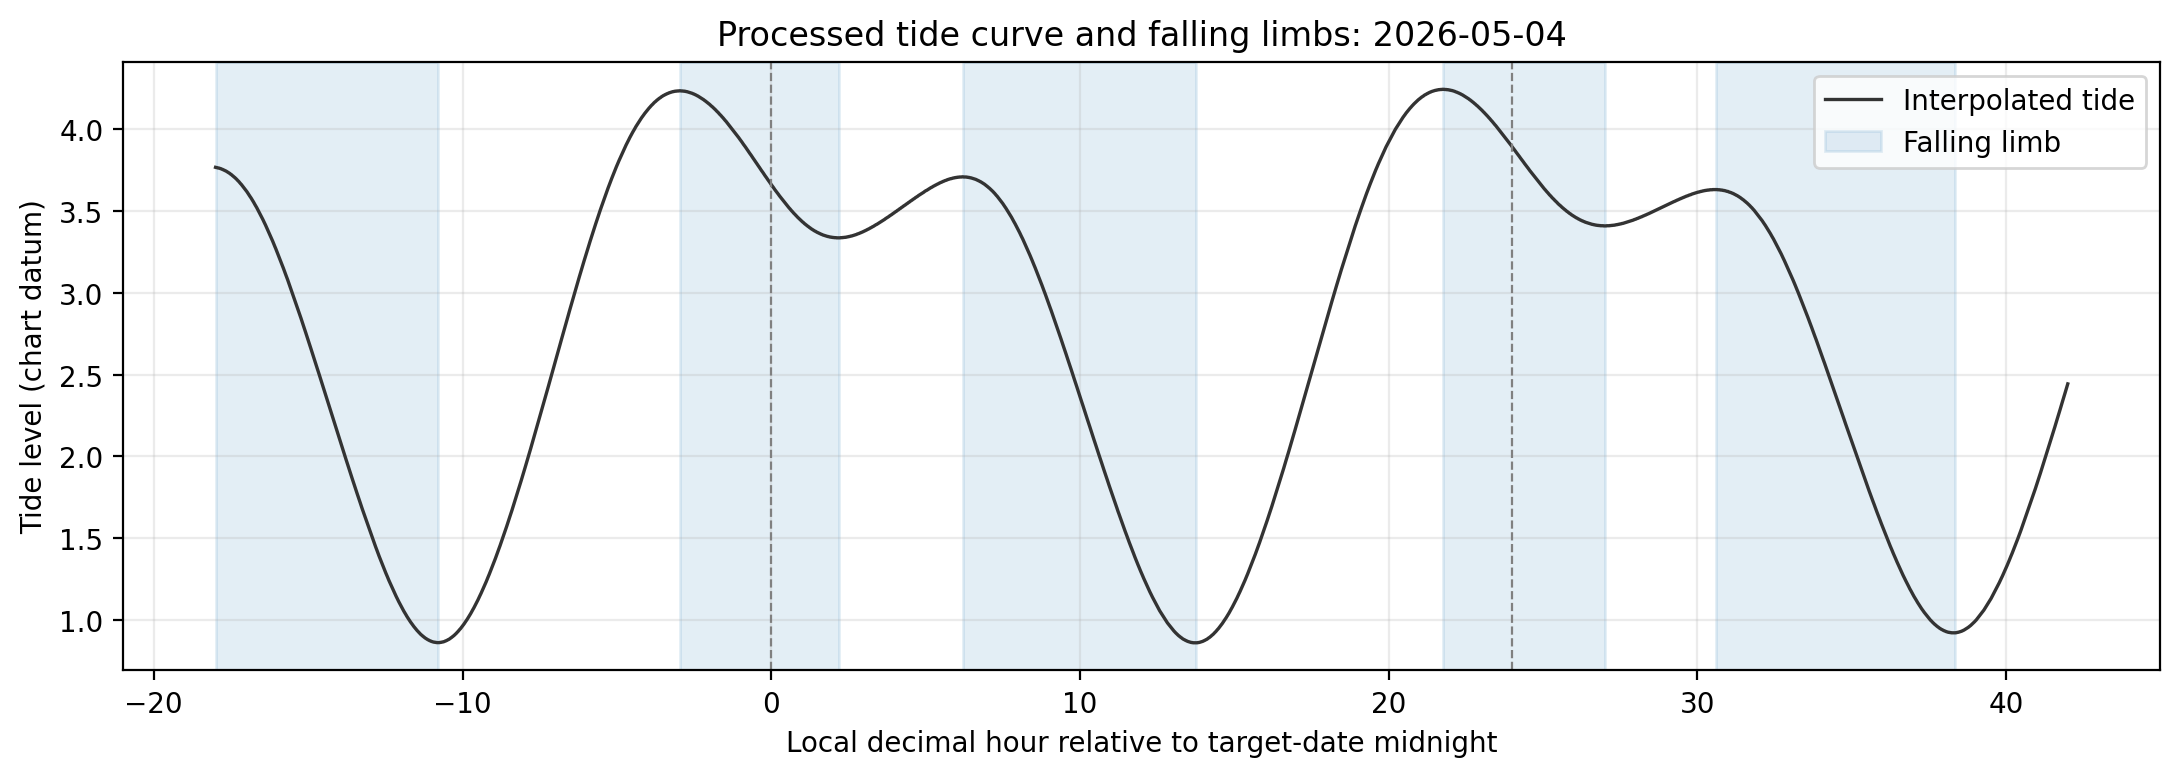

,start_hour,end_hour,high_level,low_level
0,-18.000000,-10.783333,3.768,0.862
1,-2.950000,2.200000,4.236,3.337
2,6.216667,13.766667,3.710,0.861
3,21.766667,27.016667,4.245,3.410
4,30.616667,38.333333,3.632,0.922


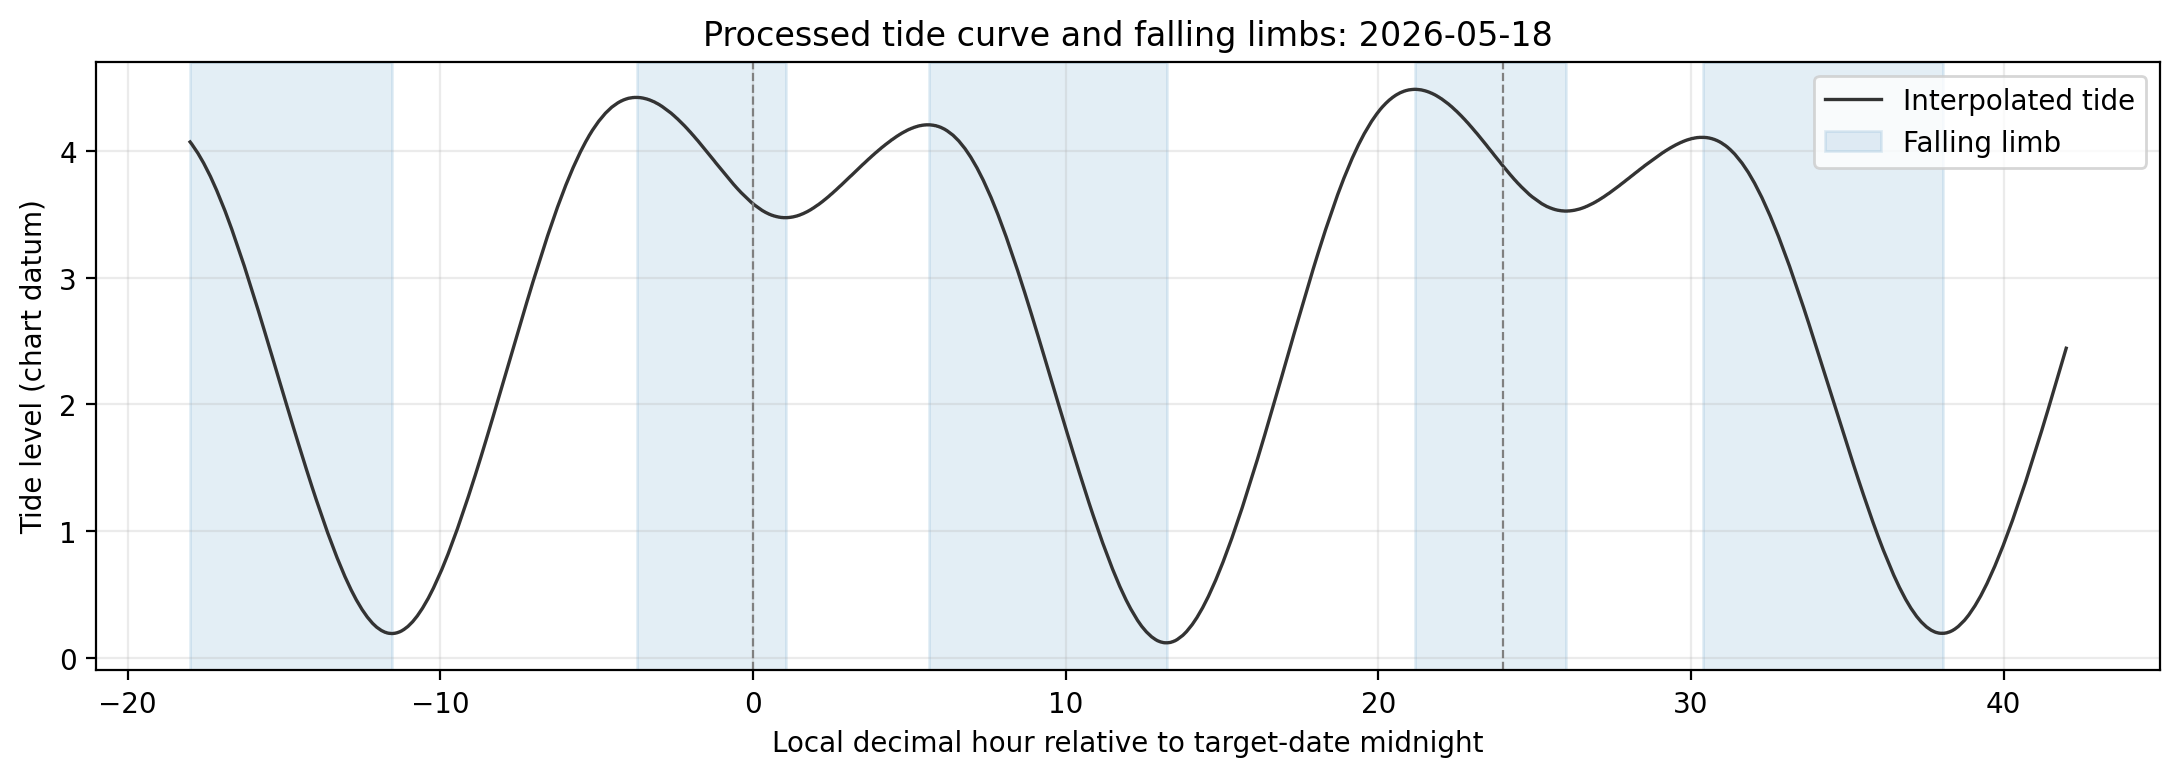

,start_hour,end_hour,high_level,low_level
0,-18.000000,-11.533333,4.070,0.193
1,-3.700000,1.066667,4.421,3.473
2,5.633333,13.233333,4.205,0.120
3,21.183333,26.016667,4.485,3.525
4,30.400000,38.066667,4.106,0.194


In [7]:

def fill_zero_derivative_signs(signs):
    """Fill zero derivative signs from neighbouring non-zero signs."""
    signs = np.asarray(signs, dtype="float64").copy()
    if signs.size == 0:
        return signs

    for index in range(1, len(signs)):
        if signs[index] == 0:
            signs[index] = signs[index - 1]

    for index in range(len(signs) - 2, -1, -1):
        if signs[index] == 0:
            signs[index] = signs[index + 1]

    return signs


def build_tide_model(tide, target_date):
    """Interpolate tide data and identify high-to-low falling limbs."""
    target_date = pd.Timestamp(target_date).normalize()
    start = target_date - pd.Timedelta(hours=TIDE_SEARCH_HOURS_BEFORE)
    end = target_date + pd.Timedelta(days=1) + pd.Timedelta(
        hours=TIDE_SEARCH_HOURS_AFTER
    )

    subset = tide.loc[(tide.index >= start) & (tide.index <= end)].copy()
    if len(subset) < 3:
        raise ValueError(
            f"Insufficient tide data around {target_date.date()}: "
            f"{len(subset)} records between {start} and {end}."
        )

    dense_index = pd.date_range(
        subset.index.min().floor(TIDE_INTERPOLATION_FREQUENCY),
        subset.index.max().ceil(TIDE_INTERPOLATION_FREQUENCY),
        freq=TIDE_INTERPOLATION_FREQUENCY,
    )
    dense = subset.reindex(dense_index).interpolate(
        method="time",
        limit_area="inside",
    )

    # Prevent interpolation across unexpectedly large source-data gaps.
    max_gap = pd.Timedelta(TIDE_MAX_INTERPOLATION_GAP)
    source_times = subset.index.sort_values()
    for left, right in zip(source_times[:-1], source_times[1:]):
        if right - left > max_gap:
            dense.loc[(dense.index > left) & (dense.index < right)] = np.nan

    dense = dense.dropna()
    if len(dense) < 3:
        raise ValueError(
            f"No usable interpolated tide curve around {target_date.date()}."
        )

    smooth = dense.rolling(
        TIDE_SMOOTHING_WINDOW,
        center=True,
        min_periods=1,
    ).mean()

    times = (
        (dense.index - target_date) / pd.Timedelta(hours=1)
    ).to_numpy(dtype="float64")
    levels = dense.to_numpy(dtype="float64")
    smooth_levels = smooth.to_numpy(dtype="float64")

    derivative = np.diff(smooth_levels)
    signs = fill_zero_derivative_signs(np.sign(derivative))

    maxima = list(np.flatnonzero((signs[:-1] > 0) & (signs[1:] < 0)) + 1)
    minima = list(np.flatnonzero((signs[:-1] < 0) & (signs[1:] > 0)) + 1)

    # Include a partial falling limb at either edge of the selected time range.
    if signs.size and signs[0] < 0:
        maxima.insert(0, 0)
    if signs.size and signs[-1] < 0:
        minima.append(len(levels) - 1)

    limbs = []
    for maximum_index in maxima:
        following_minima = [
            index for index in minima if index > maximum_index
        ]
        if not following_minima:
            continue
        minimum_index = following_minima[0]

        limb_times = times[maximum_index : minimum_index + 1]
        limb_levels = levels[maximum_index : minimum_index + 1]
        valid = np.isfinite(limb_times) & np.isfinite(limb_levels)
        limb_times = limb_times[valid]
        limb_levels = limb_levels[valid]

        if len(limb_times) < 2:
            continue

        # Enforce a non-increasing water level from high tide to low tide.
        descending_levels = np.minimum.accumulate(limb_levels)

        # Reverse to ascending elevations for np.interp, then remove duplicates.
        ascending_levels = descending_levels[::-1]
        ascending_times = limb_times[::-1]
        unique_levels, unique_indices = np.unique(
            ascending_levels,
            return_index=True,
        )
        unique_times = ascending_times[unique_indices]

        if len(unique_levels) < 2:
            continue

        limbs.append(
            {
                "start_hour": float(limb_times[0]),
                "end_hour": float(limb_times[-1]),
                "high_level": float(np.nanmax(limb_levels)),
                "low_level": float(np.nanmin(limb_levels)),
                "levels_ascending": unique_levels,
                "times_for_levels": unique_times,
            }
        )

    if not limbs:
        raise RuntimeError(
            f"No falling tide limbs were identified around "
            f"{target_date.date()}. Inspect the tide curve and smoothing setting."
        )

    return {
        "date": target_date,
        "times": times,
        "levels": levels,
        "dense_series": dense,
        "limbs": limbs,
    }


def display_tide_model(model):
    date = model["date"]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(
        model["times"],
        model["levels"],
        color="0.2",
        linewidth=1.2,
        label="Interpolated tide",
    )
    for index, limb in enumerate(model["limbs"], start=1):
        ax.axvspan(
            limb["start_hour"],
            limb["end_hour"],
            color="tab:blue",
            alpha=0.12,
            label="Falling limb" if index == 1 else None,
        )
    ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
    ax.axvline(24, color="0.5", linestyle="--", linewidth=0.8)
    ax.set(
        title=f"Processed tide curve and falling limbs: {date:%Y-%m-%d}",
        xlabel="Local decimal hour relative to target-date midnight",
        ylabel="Tide level (chart datum)",
    )
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

    display(
        pd.DataFrame(
            [
                {
                    "start_hour": limb["start_hour"],
                    "end_hour": limb["end_hour"],
                    "high_level": limb["high_level"],
                    "low_level": limb["low_level"],
                }
                for limb in model["limbs"]
            ]
        )
    )


tide_models = {}
for case_name, case in input_cases.items():
    model = build_tide_model(tide_series, case["date"])
    tide_models[case_name] = model
    display_tide_model(model)


## Pixel calculation

In [8]:

def crossing_hours_for_elevations(elevations, limb):
    """Interpolate when one falling tide limb crosses each elevation."""
    flat = np.asarray(elevations, dtype="float64").ravel()
    result = np.full(flat.shape, np.nan, dtype="float64")

    valid = (
        np.isfinite(flat)
        & (flat >= limb["levels_ascending"][0])
        & (flat <= limb["levels_ascending"][-1])
    )
    if valid.any():
        result[valid] = np.interp(
            flat[valid],
            limb["levels_ascending"],
            limb["times_for_levels"],
        )
    return result.reshape(np.shape(elevations))


def calculate_emersion_and_exposure(
    elevation,
    acquisition_hour,
    tide_model,
):
    """Calculate emersion hour, exposure duration, and acquisition tide level."""
    elevation = np.asarray(elevation, dtype="float64")
    acquisition_hour = np.asarray(acquisition_hour, dtype="float64")

    valid = (
        np.isfinite(elevation)
        & np.isfinite(acquisition_hour)
        & (acquisition_hour >= 0)
        & (acquisition_hour < 24)
    )

    tide_at_acquisition = np.full(elevation.shape, np.nan, dtype="float64")
    if valid.any():
        tide_at_acquisition[valid] = np.interp(
            acquisition_hour[valid],
            tide_model["times"],
            tide_model["levels"],
            left=np.nan,
            right=np.nan,
        )

    valid &= np.isfinite(tide_at_acquisition)
    exposed_at_acquisition = valid & (elevation > tide_at_acquisition)
    submerged_at_acquisition = valid & ~exposed_at_acquisition

    previous_crossing = np.full(elevation.shape, np.nan, dtype="float64")
    next_crossing = np.full(elevation.shape, np.nan, dtype="float64")

    for limb in tide_model["limbs"]:
        crossing = crossing_hours_for_elevations(elevation, limb)
        crossing_valid = valid & np.isfinite(crossing)

        before = crossing_valid & (crossing <= acquisition_hour)
        update_previous = before & (
            ~np.isfinite(previous_crossing)
            | (crossing > previous_crossing)
        )
        previous_crossing[update_previous] = crossing[update_previous]

        after = crossing_valid & (crossing > acquisition_hour)
        update_next = after & (
            ~np.isfinite(next_crossing)
            | (crossing < next_crossing)
        )
        next_crossing[update_next] = crossing[update_next]

    emersion_hour = np.full(elevation.shape, np.nan, dtype="float64")
    emersion_hour[exposed_at_acquisition] = previous_crossing[
        exposed_at_acquisition
    ]

    if SUBMERGED_EMERSION_MODE == "next_falling_crossing":
        emersion_hour[submerged_at_acquisition] = next_crossing[
            submerged_at_acquisition
        ]
    elif SUBMERGED_EMERSION_MODE != "nodata":
        raise ValueError(
            "SUBMERGED_EMERSION_MODE must be "
            "'next_falling_crossing' or 'nodata'."
        )

    exposure_hour = np.full(elevation.shape, np.nan, dtype="float64")

    exposed_with_crossing = (
        exposed_at_acquisition & np.isfinite(previous_crossing)
    )
    exposure_hour[exposed_with_crossing] = np.maximum(
        0.0,
        acquisition_hour[exposed_with_crossing]
        - previous_crossing[exposed_with_crossing],
    )

    # Explicit project convention: zero exposure where still submerged.
    exposure_hour[submerged_at_acquisition] = 0.0

    return {
        "emersion_hour": emersion_hour,
        "exposure_hour": exposure_hour,
        "tide_at_acquisition": tide_at_acquisition,
        "exposed_at_acquisition": exposed_at_acquisition,
        "submerged_at_acquisition": submerged_at_acquisition,
    }


## Process and write rasters

In [9]:

def initialize_output(path, profile, description, tags):
    with rasterio.open(path, "w", **profile) as destination:
        destination.set_band_description(1, description)
        destination.update_tags(**tags)


def process_case(
    *,
    case_name,
    case,
    tide_model,
):
    """Process one survey date block by block and write three COGs."""
    outputs = [
        case["aligned_acquisition_output"],
        case["emersion_output"],
        case["exposure_output"],
    ]
    if not FORCE_REDO and all(output_exists(path) for path in outputs):
        print(f"{case_name}: all outputs already exist; skipping.")
        return {
            "status": "skipped",
            "outputs": outputs,
        }

    elevation_path = raster_path(path_elevation_raster_chart_datum)
    acquisition_path = raster_path(case["acquisition_path"])

    temporary_directory = Path(tempfile.mkdtemp(prefix=f"{case_name}_emersion_"))
    local_acquisition = temporary_directory / "acquisition_aligned.tif"
    local_emersion = temporary_directory / "emersion_time.tif"
    local_exposure = temporary_directory / "exposure_time.tif"

    counters = {
        "total_pixels": 0,
        "valid_input_pixels": 0,
        "exposed_pixels": 0,
        "submerged_pixels": 0,
        "valid_emersion_pixels": 0,
        "valid_exposure_pixels": 0,
    }

    stats = {
        "elevation_min": np.inf,
        "elevation_max": -np.inf,
        "acquisition_min": np.inf,
        "acquisition_max": -np.inf,
        "emersion_min": np.inf,
        "emersion_max": -np.inf,
        "exposure_min": np.inf,
        "exposure_max": -np.inf,
    }

    try:
        with rasterio.open(elevation_path, sharing=False) as elevation_source:
            if elevation_source.crs is None:
                raise ValueError("Elevation raster has no CRS.")

            with rasterio.open(acquisition_path, sharing=False) as acquisition_source:
                if acquisition_source.crs is None:
                    raise ValueError("Acquisition-time raster has no CRS.")

                acquisition_scale, acquisition_offset = (
                    physical_band_parameters(acquisition_source, 1)
                )

                vrt_options = {
                    "crs": elevation_source.crs,
                    "transform": elevation_source.transform,
                    "width": elevation_source.width,
                    "height": elevation_source.height,
                    "resampling": Resampling.nearest,
                }
                if acquisition_source.nodata is not None:
                    vrt_options.update(
                        src_nodata=acquisition_source.nodata,
                        nodata=acquisition_source.nodata,
                    )

                with WarpedVRT(acquisition_source, **vrt_options) as acquisition_vrt:
                    output_profile = elevation_source.profile.copy()
                    output_profile.update(
                        driver="GTiff",
                        count=1,
                        dtype=OUTPUT_DTYPE,
                        nodata=OUTPUT_NODATA,
                        tiled=True,
                        blockxsize=BLOCK_SIZE,
                        blockysize=BLOCK_SIZE,
                        compress="LZW",
                        interleave="band",
                        BIGTIFF="IF_SAFER",
                    )
                    output_profile.pop("photometric", None)

                    tags = {
                        "survey_date": case["date"].strftime("%Y-%m-%d"),
                        "time_basis": "local_decimal_hour",
                        "elevation_datum": "chart_datum",
                        "acquisition_resampling": "nearest",
                    }

                    initialize_output(
                        local_acquisition,
                        output_profile,
                        "acquisition_time_local_decimal_hour",
                        tags,
                    )
                    initialize_output(
                        local_emersion,
                        output_profile,
                        "emersion_time_local_decimal_hour",
                        tags,
                    )
                    initialize_output(
                        local_exposure,
                        output_profile,
                        "exposure_duration_hours",
                        tags,
                    )

                    with (
                        rasterio.open(local_acquisition, "r+") as dst_acquisition,
                        rasterio.open(local_emersion, "r+") as dst_emersion,
                        rasterio.open(local_exposure, "r+") as dst_exposure,
                    ):
                        windows = list(elevation_source.block_windows(1))
                        total_windows = len(windows)

                        for window_number, (_, window) in enumerate(windows, start=1):
                            elevation = read_physical_band(
                                elevation_source,
                                band=1,
                                window=window,
                            )

                            acquisition_masked = acquisition_vrt.read(
                                1,
                                window=window,
                                masked=True,
                            ).astype("float64")
                            acquisition = acquisition_masked.filled(np.nan)
                            finite_acquisition = np.isfinite(acquisition)
                            acquisition[finite_acquisition] = (
                                acquisition[finite_acquisition]
                                * acquisition_scale
                                + acquisition_offset
                            )

                            result = calculate_emersion_and_exposure(
                                elevation,
                                acquisition,
                                tide_model,
                            )

                            emersion = result["emersion_hour"]
                            exposure = result["exposure_hour"]

                            valid_input = (
                                np.isfinite(elevation)
                                & np.isfinite(acquisition)
                                & (acquisition >= 0)
                                & (acquisition < 24)
                            )

                            counters["total_pixels"] += elevation.size
                            counters["valid_input_pixels"] += int(valid_input.sum())
                            counters["exposed_pixels"] += int(
                                result["exposed_at_acquisition"].sum()
                            )
                            counters["submerged_pixels"] += int(
                                result["submerged_at_acquisition"].sum()
                            )
                            counters["valid_emersion_pixels"] += int(
                                np.isfinite(emersion).sum()
                            )
                            counters["valid_exposure_pixels"] += int(
                                np.isfinite(exposure).sum()
                            )

                            value_sets = {
                                "elevation": elevation,
                                "acquisition": acquisition,
                                "emersion": emersion,
                                "exposure": exposure,
                            }
                            for name, values in value_sets.items():
                                finite_values = values[np.isfinite(values)]
                                if finite_values.size:
                                    stats[f"{name}_min"] = min(
                                        stats[f"{name}_min"],
                                        float(finite_values.min()),
                                    )
                                    stats[f"{name}_max"] = max(
                                        stats[f"{name}_max"],
                                        float(finite_values.max()),
                                    )

                            def encode(values):
                                return np.where(
                                    np.isfinite(values),
                                    values,
                                    OUTPUT_NODATA,
                                ).astype(OUTPUT_DTYPE)

                            dst_acquisition.write(
                                encode(acquisition),
                                1,
                                window=window,
                            )
                            dst_emersion.write(
                                encode(emersion),
                                1,
                                window=window,
                            )
                            dst_exposure.write(
                                encode(exposure),
                                1,
                                window=window,
                            )

                            if (
                                window_number == total_windows
                                or window_number % max(1, total_windows // 10) == 0
                            ):
                                print(
                                    f"{case_name}: processed "
                                    f"{window_number}/{total_windows} blocks"
                                )

        print(f"{case_name}: writing Cloud Optimized GeoTIFFs...")
        copy_local_gtiff_to_cog(
            local_acquisition,
            case["aligned_acquisition_output"],
        )
        copy_local_gtiff_to_cog(
            local_emersion,
            case["emersion_output"],
        )
        copy_local_gtiff_to_cog(
            local_exposure,
            case["exposure_output"],
        )

    finally:
        for local_path in (
            local_acquisition,
            local_emersion,
            local_exposure,
        ):
            try:
                local_path.unlink()
            except FileNotFoundError:
                pass
        try:
            temporary_directory.rmdir()
        except OSError:
            pass

    summary = {
        "status": "success",
        "case": case_name,
        "date": case["date"].strftime("%Y-%m-%d"),
        **counters,
        **stats,
        "aligned_acquisition_output": case["aligned_acquisition_output"],
        "emersion_output": case["emersion_output"],
        "exposure_output": case["exposure_output"],
    }
    return summary


processing_results = []
for case_name, case in input_cases.items():
    processing_results.append(
        process_case(
            case_name=case_name,
            case=case,
            tide_model=tide_models[case_name],
        )
    )

df_processing_results = pd.DataFrame(processing_results)
display(df_processing_results)


may4: processed 364/3641 blocks
may4: processed 728/3641 blocks
may4: processed 1092/3641 blocks
may4: processed 1456/3641 blocks
may4: processed 1820/3641 blocks
may4: processed 2184/3641 blocks
may4: processed 2548/3641 blocks
may4: processed 2912/3641 blocks
may4: processed 3276/3641 blocks
may4: processed 3640/3641 blocks
may4: processed 3641/3641 blocks
may4: writing Cloud Optimized GeoTIFFs...
may18: processed 364/3641 blocks
may18: processed 728/3641 blocks
may18: processed 1092/3641 blocks
may18: processed 1456/3641 blocks
may18: processed 1820/3641 blocks
may18: processed 2184/3641 blocks
may18: processed 2548/3641 blocks
may18: processed 2912/3641 blocks
may18: processed 3276/3641 blocks
may18: processed 3640/3641 blocks
may18: processed 3641/3641 blocks
may18: writing Cloud Optimized GeoTIFFs...


,status,case,date,total_pixels,valid_input_pixels,exposed_pixels,submerged_pixels,valid_emersion_pixels,valid_exposure_pixels,elevation_min,elevation_max,acquisition_min,acquisition_max,emersion_min,emersion_max,exposure_min,exposure_max,aligned_acquisition_output,emersion_output,exposure_output
0,success,may4,2026-05-04,18987815,8948474,8933224,15250,8948435,8948474,0.8295,3.96375,12.250089,13.249988,-1.109166,13.766666,0.000000,13.748004,data/processed/imagery_contextual/brunswick_ac...,data/processed/imagery_contextual/brunswick_em...,data/processed/imagery_contextual/brunswick_ex...
1,success,may18,2026-05-18,18987815,8948474,8948474,0,8948474,8948474,0.8295,3.96375,11.500089,12.499988,6.931250,11.300758,0.442522,5.019194,data/processed/imagery_contextual/brunswick_ac...,data/processed/imagery_contextual/brunswick_em...,data/processed/imagery_contextual/brunswick_ex...


## Common-valid-pixel histograms

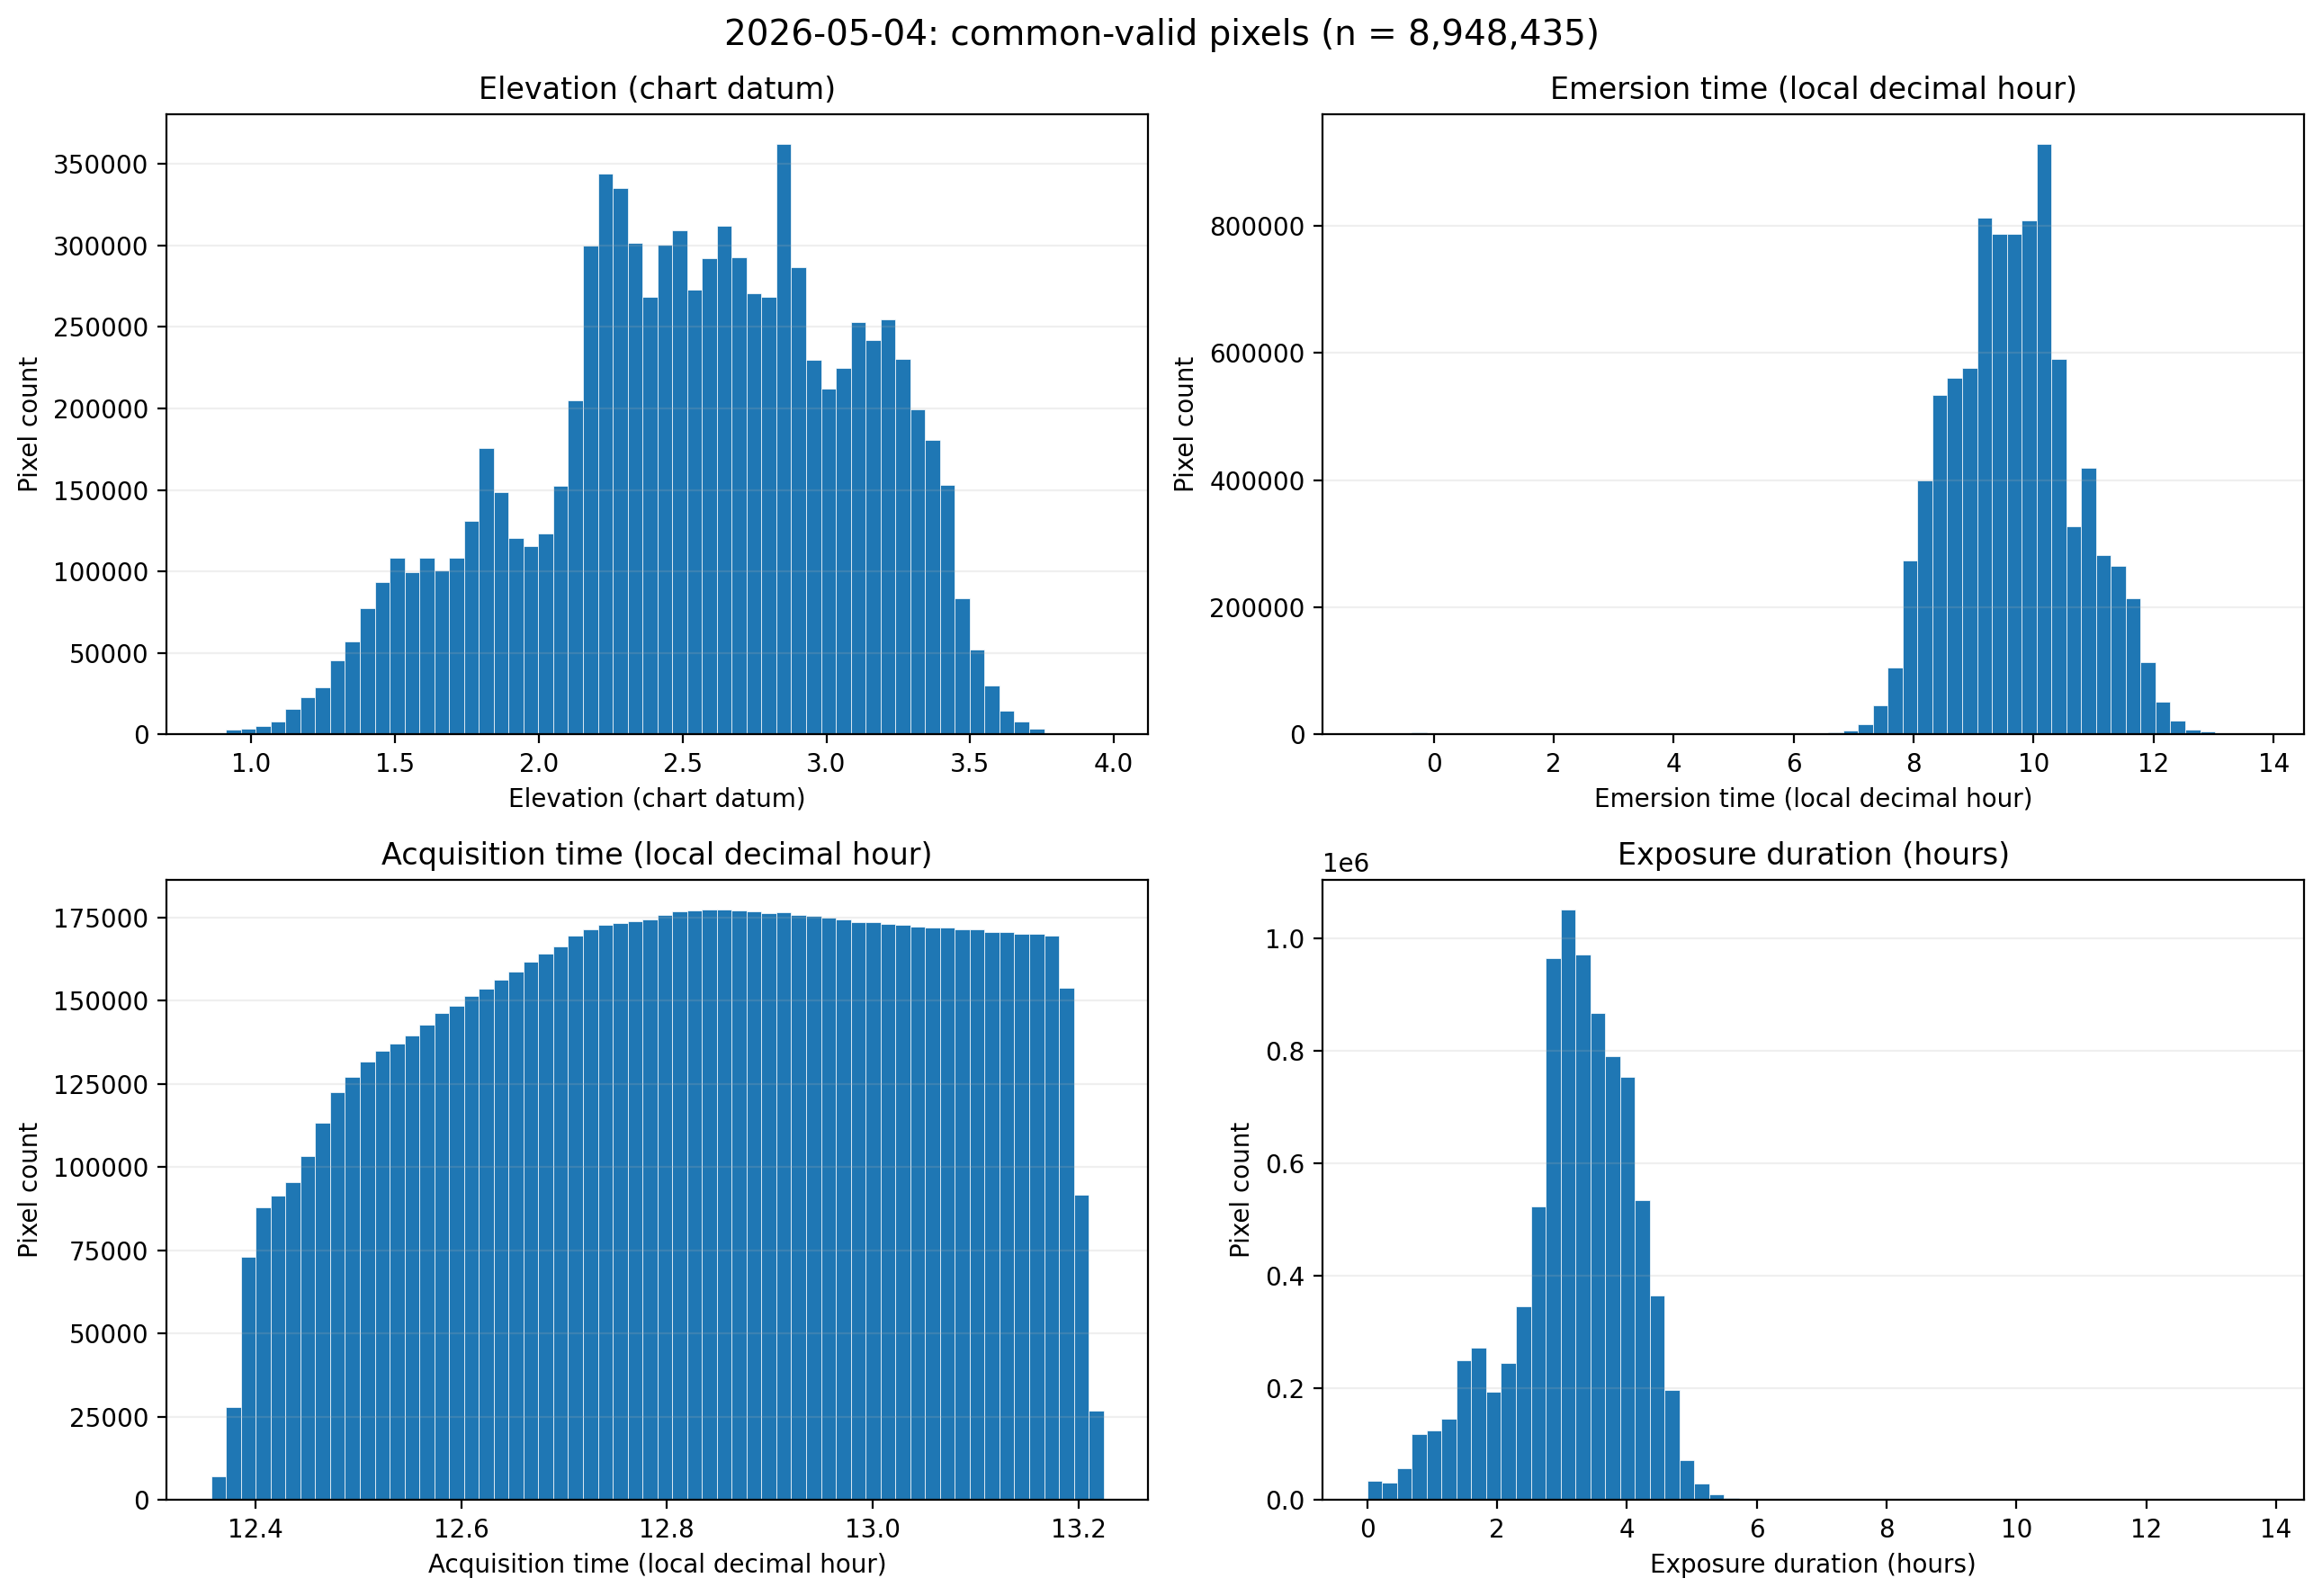

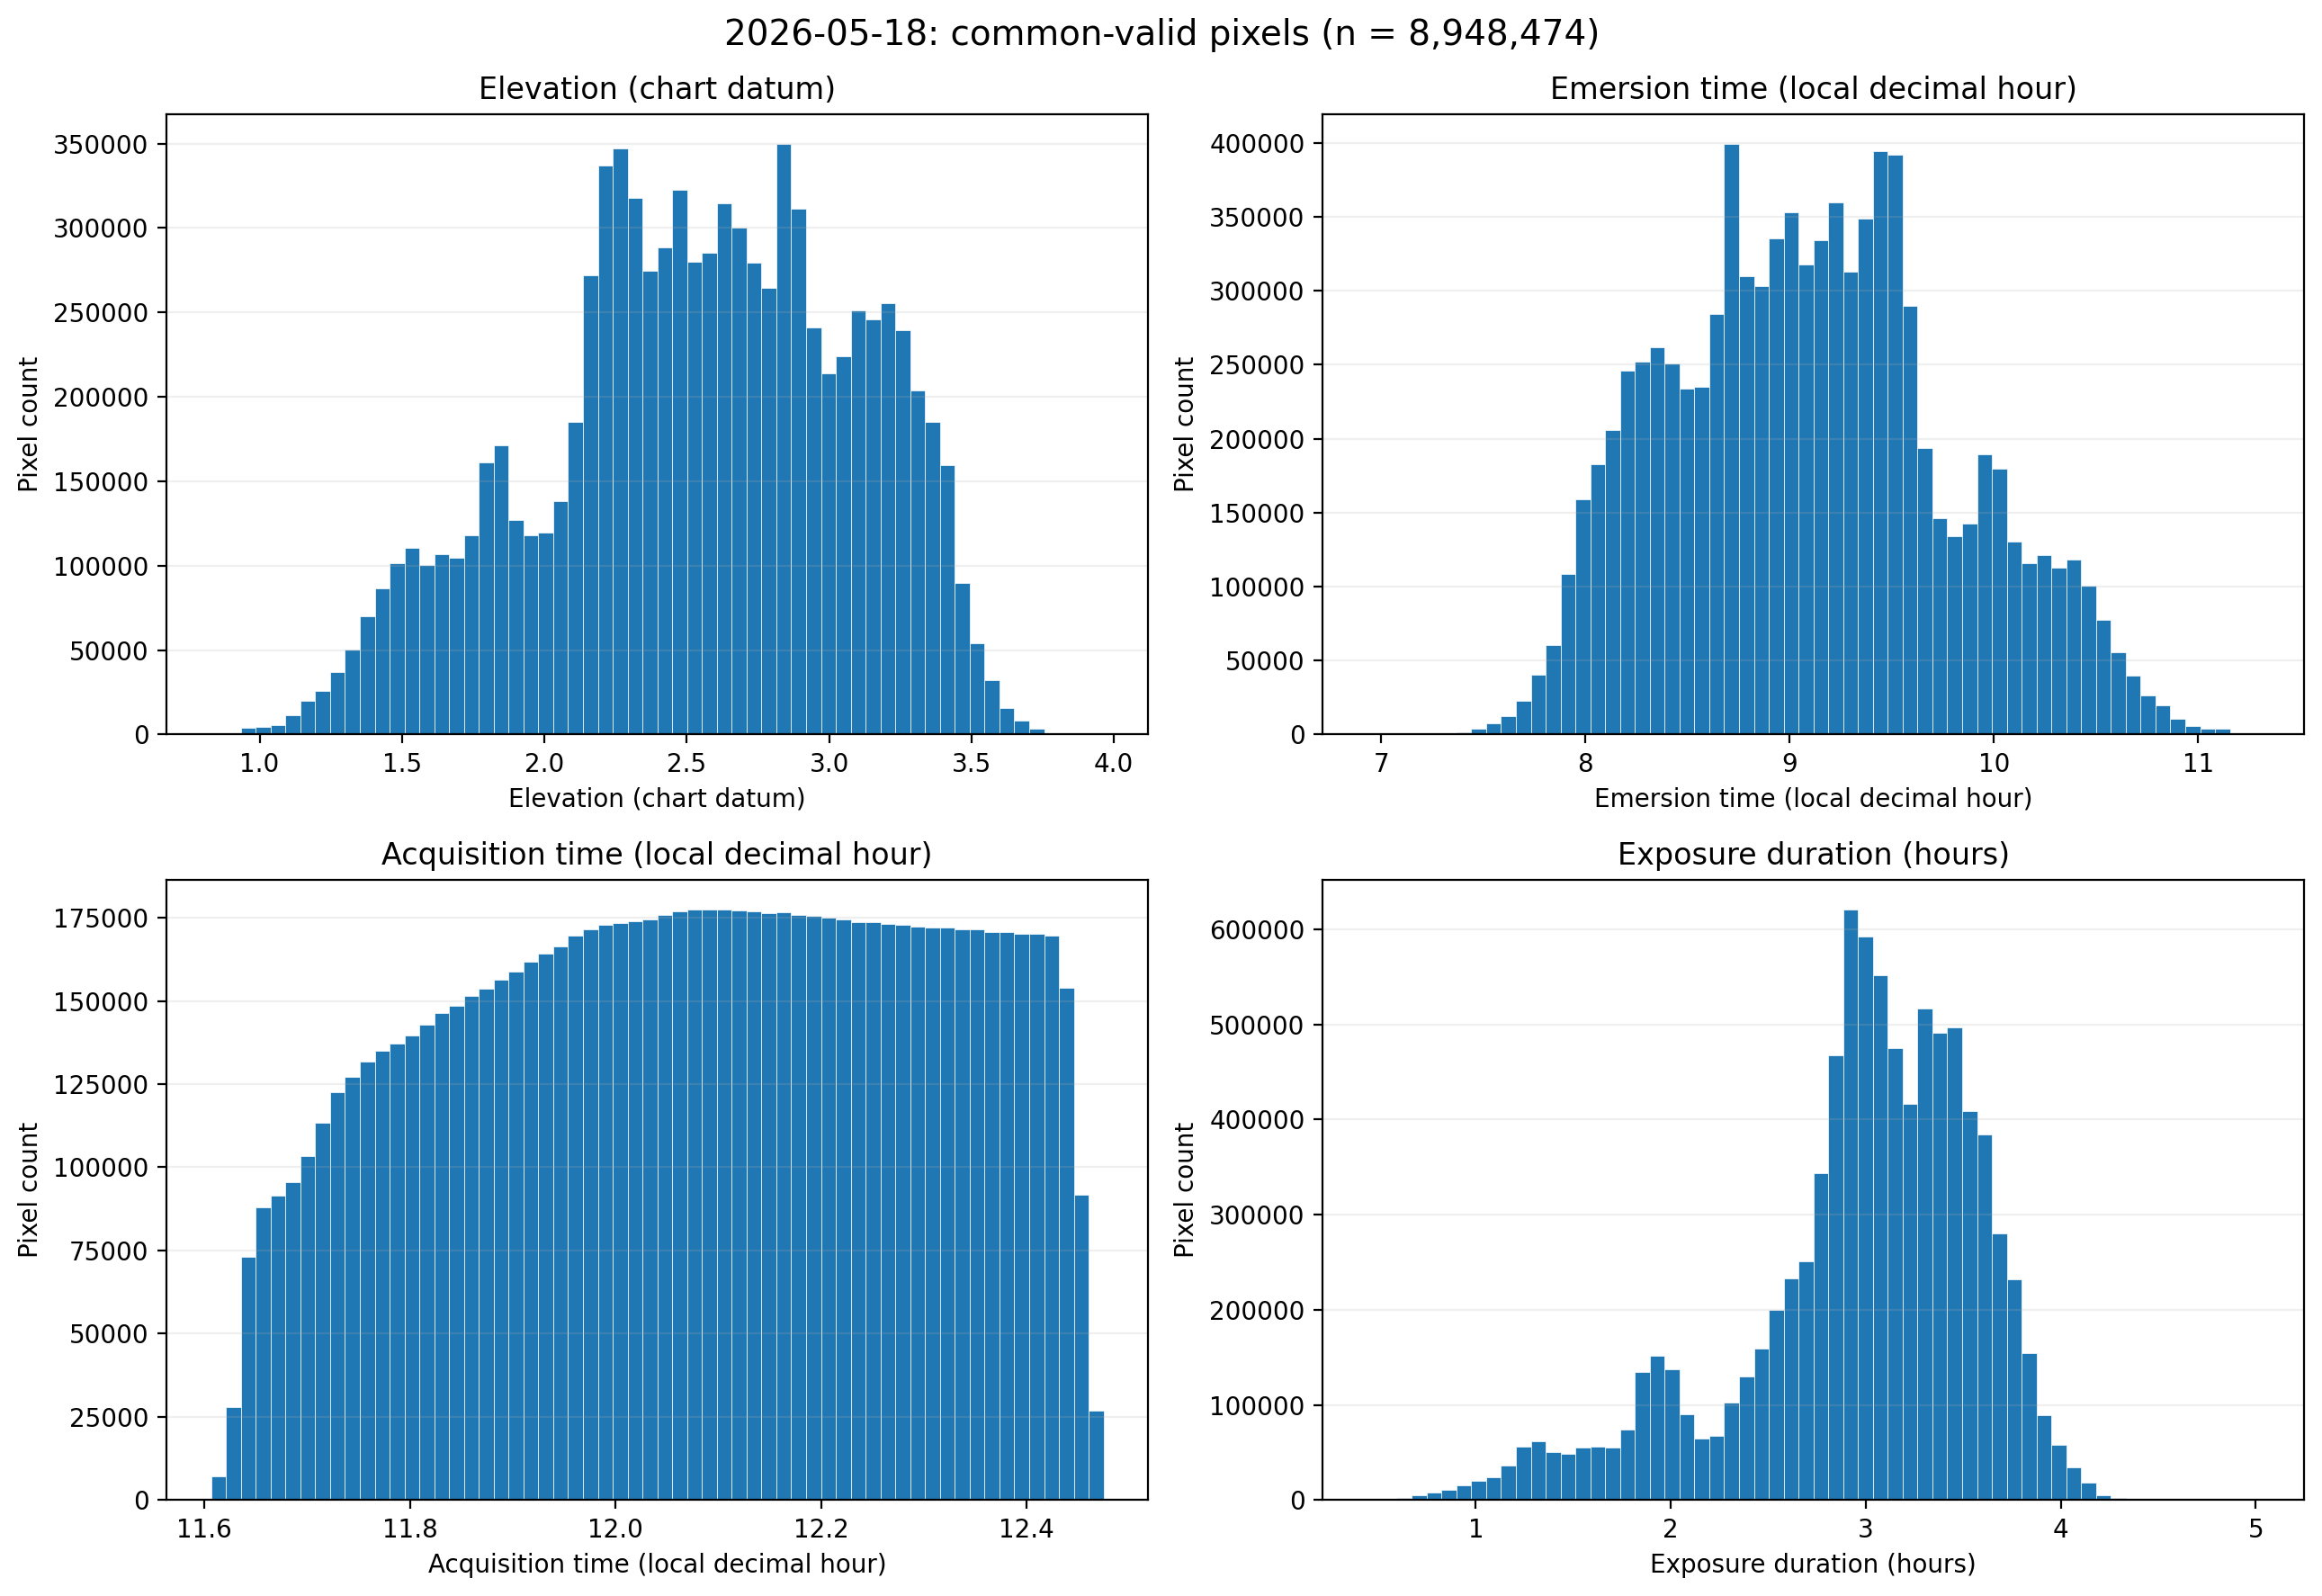

,case,date,common_valid_pixels,Elevation (chart datum)_min,Emersion time (local decimal hour)_min,Acquisition time (local decimal hour)_min,Exposure duration (hours)_min,Elevation (chart datum)_max,Emersion time (local decimal hour)_max,Acquisition time (local decimal hour)_max,Exposure duration (hours)_max
0,may4,2026-05-04,8948435,0.8610,-1.109166,12.356673,0.000000,3.96375,13.766666,13.224627,13.748004
1,may18,2026-05-18,8948474,0.8295,6.931250,11.606673,0.442522,3.96375,11.300757,12.474627,5.019195


In [10]:

def valid_raster_values(dataset, window):
    values = dataset.read(1, window=window, masked=True).astype("float64")
    return values.filled(np.nan)


def update_minimum_maximum(current, values):
    finite = values[np.isfinite(values)]
    if finite.size:
        current[0] = min(current[0], float(finite.min()))
        current[1] = max(current[1], float(finite.max()))


def histogram_edges(minimum, maximum, bins):
    if not np.isfinite(minimum) or not np.isfinite(maximum):
        raise RuntimeError("No common valid pixels were available.")
    if np.isclose(minimum, maximum):
        padding = max(0.5, abs(minimum) * 0.01)
        minimum -= padding
        maximum += padding
    return np.linspace(minimum, maximum, bins + 1)


def plot_common_valid_histograms(case_name, case):
    """Plot four exact histograms using pixels valid in all four rasters."""
    elevation_path = raster_path(path_elevation_raster_chart_datum)
    acquisition_path = raster_path(case["aligned_acquisition_output"])
    emersion_path = raster_path(case["emersion_output"])
    exposure_path = raster_path(case["exposure_output"])

    ranges = {
        "Elevation (chart datum)": [np.inf, -np.inf],
        "Emersion time (local decimal hour)": [np.inf, -np.inf],
        "Acquisition time (local decimal hour)": [np.inf, -np.inf],
        "Exposure duration (hours)": [np.inf, -np.inf],
    }
    common_count = 0

    with (
        rasterio.open(elevation_path) as elevation_source,
        rasterio.open(acquisition_path) as acquisition_source,
        rasterio.open(emersion_path) as emersion_source,
        rasterio.open(exposure_path) as exposure_source,
    ):
        elevation_scale, elevation_offset = physical_band_parameters(
            elevation_source,
            1,
        )

        # First pass: common-valid count and plotting ranges.
        for _, window in elevation_source.block_windows(1):
            elevation = valid_raster_values(elevation_source, window)
            finite_elevation = np.isfinite(elevation)
            elevation[finite_elevation] = (
                elevation[finite_elevation] * elevation_scale
                + elevation_offset
            )

            acquisition = valid_raster_values(acquisition_source, window)
            emersion = valid_raster_values(emersion_source, window)
            exposure = valid_raster_values(exposure_source, window)

            common = (
                np.isfinite(elevation)
                & np.isfinite(acquisition)
                & np.isfinite(emersion)
                & np.isfinite(exposure)
            )
            common_count += int(common.sum())
            if not common.any():
                continue

            update_minimum_maximum(
                ranges["Elevation (chart datum)"],
                elevation[common],
            )
            update_minimum_maximum(
                ranges["Emersion time (local decimal hour)"],
                emersion[common],
            )
            update_minimum_maximum(
                ranges["Acquisition time (local decimal hour)"],
                acquisition[common],
            )
            update_minimum_maximum(
                ranges["Exposure duration (hours)"],
                exposure[common],
            )

        if common_count == 0:
            raise RuntimeError(
                f"{case_name}: no pixels were valid in all four rasters."
            )

        edges = {
            name: histogram_edges(values[0], values[1], HISTOGRAM_BINS)
            for name, values in ranges.items()
        }
        counts = {
            name: np.zeros(HISTOGRAM_BINS, dtype="int64")
            for name in ranges
        }

        # Second pass: exact histograms over the same common-valid mask.
        for _, window in elevation_source.block_windows(1):
            elevation = valid_raster_values(elevation_source, window)
            finite_elevation = np.isfinite(elevation)
            elevation[finite_elevation] = (
                elevation[finite_elevation] * elevation_scale
                + elevation_offset
            )

            acquisition = valid_raster_values(acquisition_source, window)
            emersion = valid_raster_values(emersion_source, window)
            exposure = valid_raster_values(exposure_source, window)

            common = (
                np.isfinite(elevation)
                & np.isfinite(acquisition)
                & np.isfinite(emersion)
                & np.isfinite(exposure)
            )
            if not common.any():
                continue

            data_by_name = {
                "Elevation (chart datum)": elevation[common],
                "Emersion time (local decimal hour)": emersion[common],
                "Acquisition time (local decimal hour)": acquisition[common],
                "Exposure duration (hours)": exposure[common],
            }
            for name, values in data_by_name.items():
                counts[name] += np.histogram(values, bins=edges[name])[0]

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    axes = axes.ravel()

    for axis, name in zip(axes, ranges):
        bin_edges = edges[name]
        axis.bar(
            bin_edges[:-1],
            counts[name],
            width=np.diff(bin_edges),
            align="edge",
            color="tab:blue",
            edgecolor="white",
            linewidth=0.25,
        )
        axis.set(
            title=name,
            xlabel=name,
            ylabel="Pixel count",
        )
        axis.grid(axis="y", alpha=0.2)

    fig.suptitle(
        f"{case['date']:%Y-%m-%d}: common-valid pixels "
        f"(n = {common_count:,})",
        fontsize=14,
    )
    plt.tight_layout()
    plt.show()

    return {
        "case": case_name,
        "date": case["date"].strftime("%Y-%m-%d"),
        "common_valid_pixels": common_count,
        **{
            f"{name}_min": values[0]
            for name, values in ranges.items()
        },
        **{
            f"{name}_max": values[1]
            for name, values in ranges.items()
        },
    }


histogram_summaries = []
for case_name, case in input_cases.items():
    histogram_summaries.append(
        plot_common_valid_histograms(case_name, case)
    )

display(pd.DataFrame(histogram_summaries))


Pixels valid across both dates and all variables: 8,948,435
Paired pixels used for KDE: 100,000


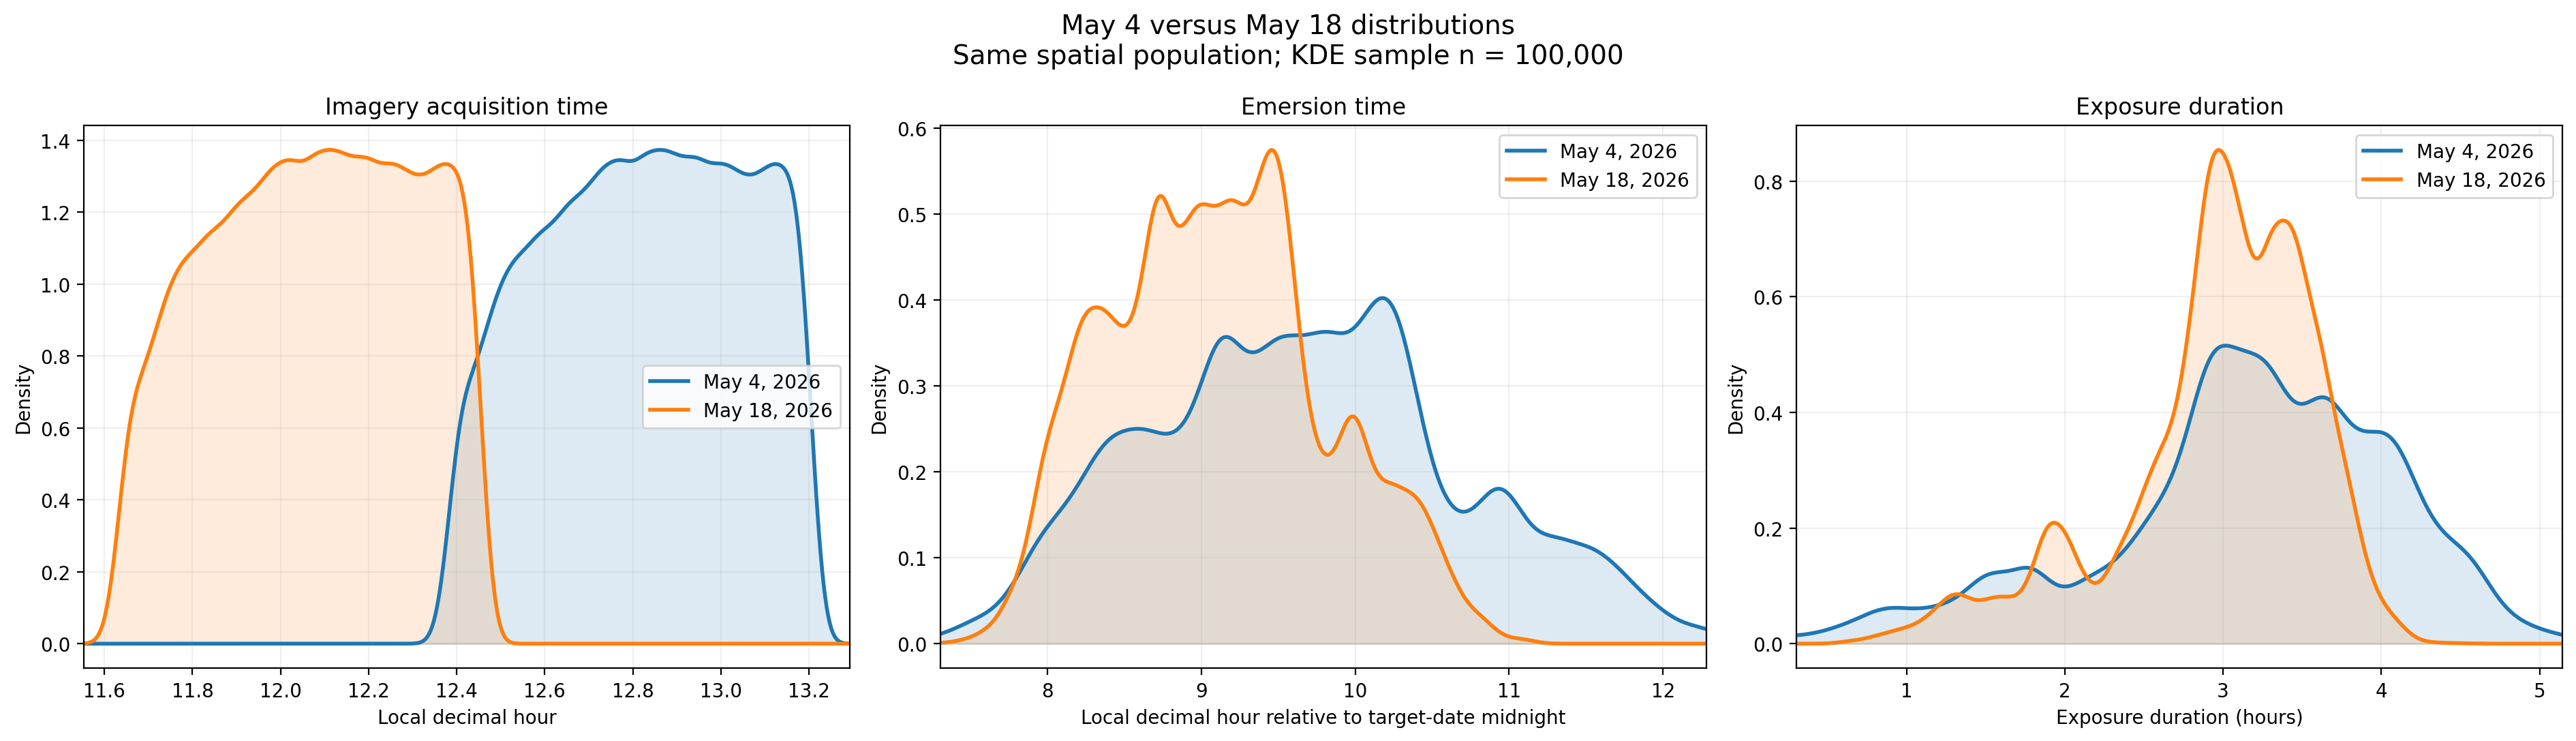

,May 4 acquisition,May 18 acquisition,May 4 emersion,May 18 emersion,May 4 exposure,May 18 exposure
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,12.823221,12.073221,9.676580,9.112588,3.146969,2.960633
std,0.225703,0.225703,1.050089,0.697650,0.968602,0.628835
min,12.357661,11.607661,-0.570833,7.262500,0.000000,0.490427
0.5%,12.387138,11.637138,7.423959,7.724584,0.310624,0.972188
5%,12.451125,11.701125,8.060119,8.037848,1.275620,1.643204
25%,12.639158,11.889158,8.942130,8.591988,2.704464,2.705486
50%,12.830559,12.080559,9.663750,9.091965,3.232683,3.054264
75%,13.015107,12.265107,10.319687,9.553606,3.811400,3.407399
95%,13.166655,12.416655,11.509895,10.366346,4.492291,3.768083


In [ ]:
# Compare May 4 and May 18 distributions for:
# 1. acquisition time,
# 2. emersion time, and
# 3. exposure duration.
#
# The comparison uses the same spatial pixels valid across both dates.

from contextlib import ExitStack
from scipy.stats import gaussian_kde

MAX_KDE_PIXELS = 100_000
KDE_RANDOM_SEED = 42

# Quantile range used to zoom the x axes around the meaningful density.
KDE_LOWER_QUANTILE = 0.005
KDE_UPPER_QUANTILE = 0.995
KDE_RANGE_PADDING_FRACTION = 0.06

may4 = input_cases["may4"]
may18 = input_cases["may18"]

comparison_paths = {
    "elevation": raster_path(
        path_elevation_raster_chart_datum
    ),
    "may4_acquisition": raster_path(
        may4["aligned_acquisition_output"]
    ),
    "may4_emersion": raster_path(
        may4["emersion_output"]
    ),
    "may4_exposure": raster_path(
        may4["exposure_output"]
    ),
    "may18_acquisition": raster_path(
        may18["aligned_acquisition_output"]
    ),
    "may18_emersion": raster_path(
        may18["emersion_output"]
    ),
    "may18_exposure": raster_path(
        may18["exposure_output"]
    ),
}


def open_comparison_sources(stack):
    """Open all rasters and confirm that they share the same grid."""
    sources = {
        name: stack.enter_context(
            rasterio.open(path)
        )
        for name, path in comparison_paths.items()
    }

    reference = sources["elevation"]
    reference_grid = (
        reference.width,
        reference.height,
        reference.transform,
        reference.crs,
    )

    for name, source in sources.items():
        source_grid = (
            source.width,
            source.height,
            source.transform,
            source.crs,
        )

        if source_grid != reference_grid:
            raise ValueError(
                f"{name!r} does not share the elevation raster grid."
            )

    return sources


def read_comparison_window(sources, window):
    """Read all comparison variables for one raster window."""
    return {
        name: valid_raster_values(source, window)
        for name, source in sources.items()
    }


def common_valid_mask(values):
    """Pixels valid in elevation and all outputs for both dates."""
    mask = np.ones(
        values["elevation"].shape,
        dtype=bool,
    )

    for array in values.values():
        mask &= np.isfinite(array)

    return mask


# -------------------------------------------------------------------------
# First pass: count pixels valid across all variables and both dates.
# -------------------------------------------------------------------------

with ExitStack() as stack:
    sources = open_comparison_sources(stack)

    common_valid_count = 0

    for _, window in sources["elevation"].block_windows(1):
        values = read_comparison_window(
            sources,
            window,
        )

        common = common_valid_mask(values)
        common_valid_count += int(common.sum())


if common_valid_count == 0:
    raise RuntimeError(
        "No spatial pixels are valid across both dates "
        "and all comparison variables."
    )

print(
    f"Pixels valid across both dates and all variables: "
    f"{common_valid_count:,}"
)


# -------------------------------------------------------------------------
# Second pass: randomly sample paired pixels for KDE.
#
# The same selected pixels are retained for every variable, ensuring that
# May 4 and May 18 use an identical spatial population.
# -------------------------------------------------------------------------

sampling_probability = min(
    1.0,
    MAX_KDE_PIXELS / common_valid_count,
)

rng = np.random.default_rng(KDE_RANDOM_SEED)

sampled_values = {
    "may4_acquisition": [],
    "may18_acquisition": [],
    "may4_emersion": [],
    "may18_emersion": [],
    "may4_exposure": [],
    "may18_exposure": [],
}

with ExitStack() as stack:
    sources = open_comparison_sources(stack)

    for _, window in sources["elevation"].block_windows(1):
        values = read_comparison_window(
            sources,
            window,
        )

        common = common_valid_mask(values)

        if not common.any():
            continue

        selected = (
            common
            & (
                rng.random(common.shape)
                < sampling_probability
            )
        )

        if not selected.any():
            continue

        for name in sampled_values:
            sampled_values[name].append(
                values[name][selected]
            )


sampled_values = {
    name: np.concatenate(arrays)
    for name, arrays in sampled_values.items()
}

available_sample_count = len(
    sampled_values["may4_acquisition"]
)

if available_sample_count < 2:
    raise RuntimeError(
        "Too few common-valid pixels were sampled for KDE."
    )

# Enforce the maximum sample count while retaining paired pixels.
if available_sample_count > MAX_KDE_PIXELS:
    selected_indexes = rng.choice(
        available_sample_count,
        size=MAX_KDE_PIXELS,
        replace=False,
    )

    sampled_values = {
        name: values[selected_indexes]
        for name, values in sampled_values.items()
    }

sample_count = len(
    sampled_values["may4_acquisition"]
)

print(f"Paired pixels used for KDE: {sample_count:,}")


# -------------------------------------------------------------------------
# Plotting helpers
# -------------------------------------------------------------------------

def significant_plot_range(
    first_values,
    second_values,
    *,
    lower_bound=None,
    upper_bound=None,
):
    """
    Calculate an x-axis range based on the central density of both dates.

    The default range spans the 0.5th to 99.5th percentiles, with a small
    amount of padding. Optional hard bounds can then be applied.
    """
    combined = np.concatenate(
        [
            np.asarray(first_values, dtype="float64"),
            np.asarray(second_values, dtype="float64"),
        ]
    )

    combined = combined[np.isfinite(combined)]

    minimum, maximum = np.quantile(
        combined,
        [
            KDE_LOWER_QUANTILE,
            KDE_UPPER_QUANTILE,
        ],
    )

    if np.isclose(minimum, maximum):
        padding = max(
            0.1,
            abs(float(minimum)) * 0.05,
        )
    else:
        padding = (
            float(maximum - minimum)
            * KDE_RANGE_PADDING_FRACTION
        )

    minimum = float(minimum - padding)
    maximum = float(maximum + padding)

    if lower_bound is not None:
        minimum = max(minimum, lower_bound)

    if upper_bound is not None:
        maximum = min(maximum, upper_bound)

    if maximum <= minimum:
        maximum = minimum + 0.1

    return minimum, maximum


def evaluate_kde(values, x_values):
    """
    Evaluate Gaussian KDE, with a fallback for nearly constant data.

    Gaussian KDE cannot be calculated when all sampled values are identical.
    """
    values = np.asarray(
        values,
        dtype="float64",
    )
    values = values[np.isfinite(values)]

    if len(values) < 2:
        return None

    if np.isclose(
        np.nanmin(values),
        np.nanmax(values),
    ):
        return None

    kde = gaussian_kde(values)
    return kde(x_values)


def plot_comparison_kde(
    axis,
    may4_values,
    may18_values,
    *,
    title,
    xlabel,
    lower_bound=None,
    upper_bound=None,
):
    """Plot May 4 and May 18 kernel-density curves."""
    plot_minimum, plot_maximum = (
        significant_plot_range(
            may4_values,
            may18_values,
            lower_bound=lower_bound,
            upper_bound=upper_bound,
        )
    )

    x_values = np.linspace(
        plot_minimum,
        plot_maximum,
        500,
    )

    plot_specs = [
        {
            "values": may4_values,
            "label": "May 4, 2026",
            "color": "tab:blue",
        },
        {
            "values": may18_values,
            "label": "May 18, 2026",
            "color": "tab:orange",
        },
    ]

    for specification in plot_specs:
        density = evaluate_kde(
            specification["values"],
            x_values,
        )

        if density is None:
            # Constant or nearly constant distributions are shown as a
            # vertical reference line instead.
            representative_value = float(
                np.nanmedian(
                    specification["values"]
                )
            )

            axis.axvline(
                representative_value,
                color=specification["color"],
                linewidth=2,
                label=(
                    f"{specification['label']} "
                    f"(constant: {representative_value:.3f})"
                ),
            )
            continue

        axis.plot(
            x_values,
            density,
            color=specification["color"],
            linewidth=2,
            label=specification["label"],
        )

        axis.fill_between(
            x_values,
            density,
            color=specification["color"],
            alpha=0.15,
        )

    axis.set(
        title=title,
        xlabel=xlabel,
        ylabel="Density",
        xlim=(plot_minimum, plot_maximum),
    )

    axis.grid(
        axis="both",
        alpha=0.2,
    )

    axis.legend()


# -------------------------------------------------------------------------
# KDE comparison plots
# -------------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 5.5),
)

plot_comparison_kde(
    axes[0],
    sampled_values["may4_acquisition"],
    sampled_values["may18_acquisition"],
    title="Acquisition time",
    xlabel="Local decimal hour",
    lower_bound=0,
    upper_bound=24,
)

plot_comparison_kde(
    axes[1],
    sampled_values["may4_emersion"],
    sampled_values["may18_emersion"],
    title="Emersion time",
    xlabel=(
        "Local decimal hour"
    ),
)

plot_comparison_kde(
    axes[2],
    sampled_values["may4_exposure"],
    sampled_values["may18_exposure"],
    title="Exposure duration",
    xlabel="Exposure duration (hours)",
    lower_bound=0,
)

fig.suptitle(
    "May 4 versus May 18 distributions\n"
    f"Same spatial population; KDE sample n = {sample_count:,}",
    fontsize=14,
)

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# Numerical comparison
# -------------------------------------------------------------------------

comparison_dataframe = pd.DataFrame(
    {
        "May 4 acquisition": (
            sampled_values["may4_acquisition"]
        ),
        "May 18 acquisition": (
            sampled_values["may18_acquisition"]
        ),
        "May 4 emersion": (
            sampled_values["may4_emersion"]
        ),
        "May 18 emersion": (
            sampled_values["may18_emersion"]
        ),
        "May 4 exposure": (
            sampled_values["may4_exposure"]
        ),
        "May 18 exposure": (
            sampled_values["may18_exposure"]
        ),
    }
)

comparison_summary = comparison_dataframe.describe(
    percentiles=[
        0.005,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.995,
    ]
)

display(comparison_summary)

Round/date mapping used for ground samples:
  may4: round 1 → 2026-05-04
  may18: round 2 → 2026-05-18
Ground records retained for site 'brunswick': 60
may4_acquisition: 30 valid stations
may18_acquisition: 30 valid stations
may4_emersion: 30 valid stations
may18_emersion: 30 valid stations
may4_exposure: 30 valid stations
may18_exposure: 30 valid stations


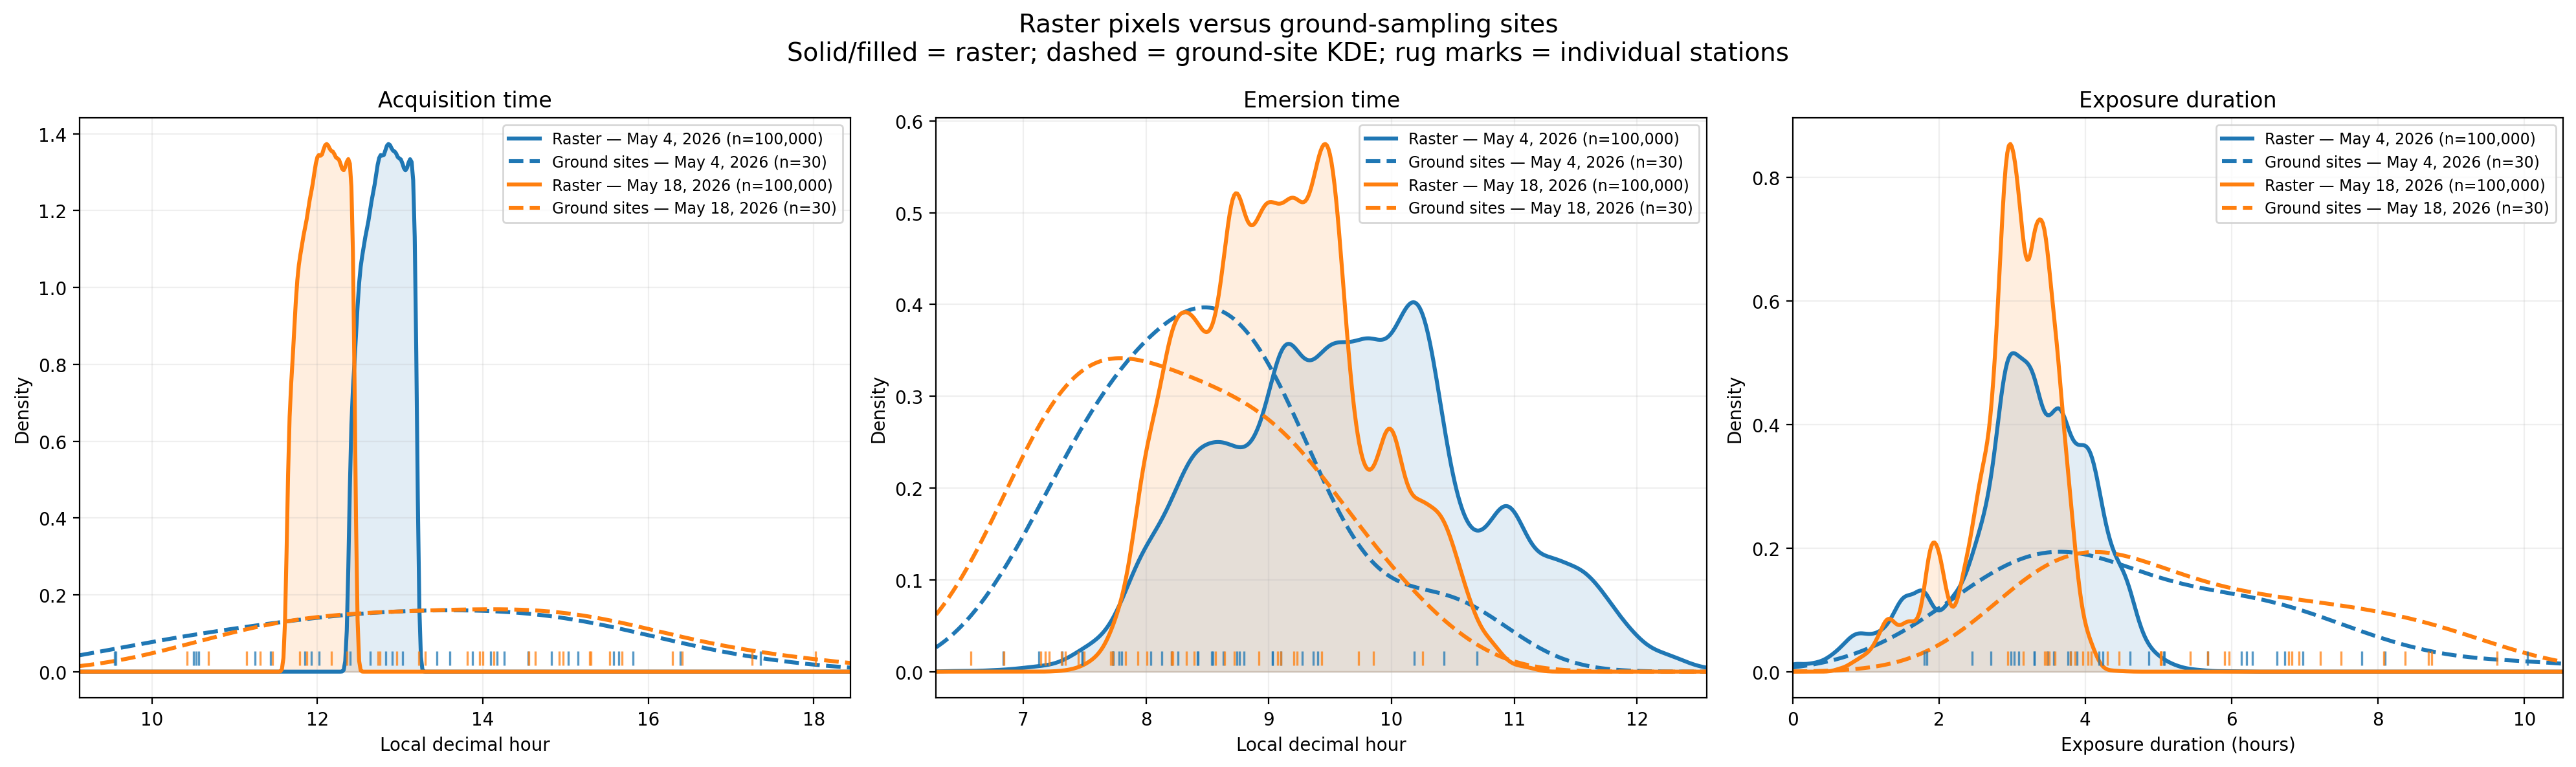

,May 4 acquisition,May 18 acquisition,May 4 emersion,May 18 emersion,May 4 exposure,May 18 exposure
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,13.227176,13.766148,8.508620,8.253343,4.718541,5.512812
std,2.050146,1.979855,0.937528,0.954574,1.982827,1.934565
min,9.549722,10.428611,6.836667,6.575000,1.796764,2.942833
5%,9.988736,10.890986,7.212389,6.976611,2.111236,3.283221
25%,11.871736,12.219444,7.785069,7.460694,3.301073,3.888035
50%,13.239861,13.885000,8.477778,8.211111,4.212382,5.032785
75%,14.758194,15.209236,9.027986,9.031111,6.186612,6.895248
95%,16.130694,16.875806,10.314889,9.797917,7.949712,8.711898
max,17.357500,18.018611,10.697500,10.253333,10.043054,9.627884


In [ ]:
# Compare raster distributions with values measured at ground-sampling sites.
#
# Raster KDEs:
#   - solid lines with transparent fill
#
# Ground-site KDEs:
#   - dashed lines without fill
#   - rug marks show individual station values
#
# df_all_R index:
#   ['site', 'round', 'station_id']
#
# df_all_R columns:
#   emergence_time_hours
#   acquisition_time_hours
#   emergence_acquisition_time_difference_hours

GROUND_KDE_BW_ADJUST = 1.0
SHOW_GROUND_RUG_MARKS = True

ground_column_by_variable = {
    "acquisition": "acquisition_time_hours",
    "emersion": "emergence_time_hours",
    "exposure": (
        "emergence_acquisition_time_difference_hours"
    ),
}

raster_key_by_variable = {
    "acquisition": {
        "may4": "may4_acquisition",
        "may18": "may18_acquisition",
    },
    "emersion": {
        "may4": "may4_emersion",
        "may18": "may18_emersion",
    },
    "exposure": {
        "may4": "may4_exposure",
        "may18": "may18_exposure",
    },
}

plot_settings = {
    "acquisition": {
        "title": "Acquisition time",
        "xlabel": "Local decimal hour",
        "lower_bound": 0,
        "upper_bound": 24,
    },
    "emersion": {
        "title": "Emersion time",
        "xlabel": (
            "Local decimal hour"
        ),
        "lower_bound": None,
        "upper_bound": None,
    },
    "exposure": {
        "title": "Exposure duration",
        "xlabel": "Exposure duration (hours)",
        "lower_bound": 0,
        "upper_bound": None,
    },
}

date_colors = {
    "may4": "tab:blue",
    "may18": "tab:orange",
}


# -------------------------------------------------------------------------
# Identify the rounds corresponding to the two imagery dates.
# -------------------------------------------------------------------------

dates_by_round = {
    round_number: pd.Timestamp(date).normalize()
    for round_number, date
    in config.IMAGERY["dates_by_round"].items()
}


def find_round_for_date(date):
    """Return the configured sampling round for a survey date."""
    normalized_date = pd.Timestamp(date).normalize()

    matching_rounds = [
        round_number
        for round_number, configured_date
        in dates_by_round.items()
        if configured_date == normalized_date
    ]

    if len(matching_rounds) != 1:
        raise ValueError(
            f"Expected exactly one round for "
            f"{normalized_date.date()}, but found "
            f"{matching_rounds}."
        )

    return matching_rounds[0]


round_by_case = {
    case_name: find_round_for_date(case["date"])
    for case_name, case in input_cases.items()
}

print("Round/date mapping used for ground samples:")
for case_name, round_number in round_by_case.items():
    print(
        f"  {case_name}: round {round_number} → "
        f"{dates_by_round[round_number].date()}"
    )


# -------------------------------------------------------------------------
# Validate and filter df_all_R.
# -------------------------------------------------------------------------

required_index_levels = {
    "site",
    "round",
    "station_id",
}

if not isinstance(df_all_R.index, pd.MultiIndex):
    raise TypeError(
        "df_all_R must have a pandas MultiIndex."
    )

missing_index_levels = (
    required_index_levels
    - set(df_all_R.index.names)
)

if missing_index_levels:
    raise ValueError(
        "df_all_R is missing required index levels: "
        f"{sorted(missing_index_levels)}"
    )

required_ground_columns = set(
    ground_column_by_variable.values()
)

missing_ground_columns = (
    required_ground_columns
    - set(df_all_R.columns)
)

if missing_ground_columns:
    raise ValueError(
        "df_all_R is missing required columns: "
        f"{sorted(missing_ground_columns)}"
    )


# Select the site represented by the Brunswick raster.
site_values = (
    df_all_R.index
    .get_level_values("site")
    .astype("string")
    .str.strip()
    .str.lower()
)

site_mask = (
    site_values
    == str(SITE_VALUE).strip().lower()
)

df_ground_site = df_all_R.loc[
    site_mask
].copy()

if df_ground_site.empty:
    raise ValueError(
        f"No ground-sampling records were found for "
        f"site {SITE_VALUE!r}."
    )

print(
    f"Ground records retained for site "
    f"{SITE_VALUE!r}: {len(df_ground_site):,}"
)


# -------------------------------------------------------------------------
# Extract ground values by date and variable.
# -------------------------------------------------------------------------

def ground_values_for_round(
    dataframe,
    *,
    round_number,
    column,
):
    """Return finite numeric ground values for one round."""
    round_values = (
        dataframe.index
        .get_level_values("round")
    )

    # Support either numeric or string round labels.
    mask = (
        round_values.astype("string")
        == str(round_number)
    )

    values = pd.to_numeric(
        dataframe.loc[mask, column],
        errors="coerce",
    )

    return values[
        np.isfinite(values)
    ].to_numpy(dtype="float64")


ground_values = {}

for variable, column in (
    ground_column_by_variable.items()
):
    for case_name, round_number in (
        round_by_case.items()
    ):
        key = f"{case_name}_{variable}"

        ground_values[key] = (
            ground_values_for_round(
                df_ground_site,
                round_number=round_number,
                column=column,
            )
        )

        print(
            f"{key}: "
            f"{len(ground_values[key]):,} valid stations"
        )


# -------------------------------------------------------------------------
# KDE helper functions.
# -------------------------------------------------------------------------

def evaluate_adjusted_kde(
    values,
    x_values,
    *,
    bandwidth_adjustment=1.0,
):
    """
    Evaluate a Gaussian KDE with an optional bandwidth adjustment.

    Returns None if too few distinct values are available.
    """
    values = np.asarray(
        values,
        dtype="float64",
    )
    values = values[np.isfinite(values)]

    if len(values) < 2:
        return None

    if np.isclose(
        np.nanmin(values),
        np.nanmax(values),
    ):
        return None

    def adjusted_bandwidth(kde):
        return (
            kde.scotts_factor()
            * bandwidth_adjustment
        )

    kde = gaussian_kde(
        values,
        bw_method=adjusted_bandwidth,
    )

    return kde(x_values)

GROUND_RANGE_PADDING_FRACTION = 0.05


def raster_and_ground_plot_range(
    may4_raster,
    may18_raster,
    may4_ground,
    may18_ground,
    *,
    lower_bound=None,
    upper_bound=None,
):
    """
    Calculate a plot range that includes:

    1. the significant central range of the raster distributions; and
    2. all finite ground-sampling values.

    This retains the raster-density zoom while ensuring that every ground
    observation is visible.
    """
    raster_minimum, raster_maximum = (
        significant_plot_range(
            may4_raster,
            may18_raster,
        )
    )

    ground_combined = np.concatenate(
        [
            np.asarray(
                may4_ground,
                dtype="float64",
            ),
            np.asarray(
                may18_ground,
                dtype="float64",
            ),
        ]
    )

    ground_combined = ground_combined[
        np.isfinite(ground_combined)
    ]

    if ground_combined.size:
        minimum = min(
            raster_minimum,
            float(ground_combined.min()),
        )
        maximum = max(
            raster_maximum,
            float(ground_combined.max()),
        )
    else:
        minimum = raster_minimum
        maximum = raster_maximum

    # Add padding after combining raster and ground ranges.
    if np.isclose(minimum, maximum):
        padding = max(
            0.1,
            abs(minimum) * 0.05,
        )
    else:
        padding = (
            maximum - minimum
        ) * GROUND_RANGE_PADDING_FRACTION

    minimum -= padding
    maximum += padding

    # Apply physically meaningful hard limits.
    if lower_bound is not None:
        minimum = max(
            minimum,
            lower_bound,
        )

    if upper_bound is not None:
        maximum = min(
            maximum,
            upper_bound,
        )

    if maximum <= minimum:
        maximum = minimum + 0.1

    return minimum, maximum

def plot_raster_and_ground_comparison(
    axis,
    *,
    variable,
    title,
    xlabel,
    lower_bound=None,
    upper_bound=None,
):
    """
    Plot raster KDEs with fill and ground-site KDEs as dashed lines.
    """
    may4_raster = sampled_values[
        raster_key_by_variable[variable]["may4"]
    ]
    may18_raster = sampled_values[
        raster_key_by_variable[variable]["may18"]
    ]

    # The x-axis zoom is based primarily on the much larger raster
    # distributions. Ground observations do not expand the plot range
    # solely because of one extreme station value.
    may4_ground = ground_values[
        f"may4_{variable}"
    ]

    may18_ground = ground_values[
        f"may18_{variable}"
    ]

    plot_minimum, plot_maximum = (
        raster_and_ground_plot_range(
            may4_raster,
            may18_raster,
            may4_ground,
            may18_ground,
            lower_bound=lower_bound,
            upper_bound=upper_bound,
        )
    )
    x_values = np.linspace(
        plot_minimum,
        plot_maximum,
        500,
    )

    maximum_density = 0.0

    for case_name, date_label in (
        ("may4", "May 4, 2026"),
        ("may18", "May 18, 2026"),
    ):
        color = date_colors[case_name]

        raster_values = sampled_values[
            raster_key_by_variable[
                variable
            ][case_name]
        ]

        station_values = ground_values[
            f"{case_name}_{variable}"
        ]

        # -------------------------------------------------------------
        # Raster KDE: solid line with fill.
        # -------------------------------------------------------------
        raster_density = evaluate_adjusted_kde(
            raster_values,
            x_values,
        )

        if raster_density is not None:
            maximum_density = max(
                maximum_density,
                float(np.nanmax(raster_density)),
            )

            axis.plot(
                x_values,
                raster_density,
                color=color,
                linewidth=2.2,
                linestyle="-",
                label=(
                    f"Raster — {date_label} "
                    f"(n={len(raster_values):,})"
                ),
            )

            axis.fill_between(
                x_values,
                raster_density,
                color=color,
                alpha=0.13,
            )

        # -------------------------------------------------------------
        # Ground-site KDE: dashed line without fill.
        # -------------------------------------------------------------
        ground_density = evaluate_adjusted_kde(
            station_values,
            x_values,
            bandwidth_adjustment=(
                GROUND_KDE_BW_ADJUST
            ),
        )

        if ground_density is not None:
            maximum_density = max(
                maximum_density,
                float(np.nanmax(ground_density)),
            )

            axis.plot(
                x_values,
                ground_density,
                color=color,
                linewidth=2.2,
                linestyle="--",
                label=(
                    f"Ground sites — {date_label} "
                    f"(n={len(station_values):,})"
                ),
            )

        elif len(station_values) > 0:
            # A KDE cannot be estimated for one value or for identical
            # station values. Show the median as a dotted line instead.
            representative_value = float(
                np.nanmedian(station_values)
            )

            axis.axvline(
                representative_value,
                color=color,
                linewidth=2,
                linestyle=":",
                label=(
                    f"Ground sites — {date_label} "
                    f"(median={representative_value:.2f}; "
                    f"n={len(station_values):,})"
                ),
            )

    axis.set(
        title=title,
        xlabel=xlabel,
        ylabel="Density",
        xlim=(plot_minimum, plot_maximum),
    )

    axis.grid(
        axis="both",
        alpha=0.2,
    )

    # Add individual ground observations as rug marks.
    if SHOW_GROUND_RUG_MARKS:
        rug_height = (
            maximum_density * 0.025
            if maximum_density > 0
            else 0.01
        )

        for case_name in ("may4", "may18"):
            station_values = ground_values[
                f"{case_name}_{variable}"
            ]

            visible_values = station_values[
                (station_values >= plot_minimum)
                & (station_values <= plot_maximum)
            ]

            if len(visible_values):
                axis.plot(
                    visible_values,
                    np.full(
                        len(visible_values),
                        rug_height,
                    ),
                    linestyle="None",
                    marker="|",
                    markersize=8,
                    markeredgewidth=1.2,
                    color=date_colors[case_name],
                    alpha=0.75,
                )

    axis.legend(
        fontsize=8.5,
    )


# -------------------------------------------------------------------------
# Plot raster and ground distributions together.
# -------------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 6),
)

for axis, variable in zip(
    axes,
    ("acquisition", "emersion", "exposure"),
):
    settings = plot_settings[variable]

    plot_raster_and_ground_comparison(
        axis,
        variable=variable,
        title=settings["title"],
        xlabel=settings["xlabel"],
        lower_bound=settings["lower_bound"],
        upper_bound=settings["upper_bound"],
    )

fig.suptitle(
    "Raster pixels versus ground-sampling sites\n"
    "Solid/filled = raster; dashed = ground-site KDE; "
    "rug marks = individual stations",
    fontsize=14,
)

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# Numerical summary of ground observations.
# -------------------------------------------------------------------------

ground_comparison_summary = pd.DataFrame(
    {
        "May 4 acquisition": pd.Series(
            ground_values["may4_acquisition"]
        ),
        "May 18 acquisition": pd.Series(
            ground_values["may18_acquisition"]
        ),
        "May 4 emersion": pd.Series(
            ground_values["may4_emersion"]
        ),
        "May 18 emersion": pd.Series(
            ground_values["may18_emersion"]
        ),
        "May 4 exposure": pd.Series(
            ground_values["may4_exposure"]
        ),
        "May 18 exposure": pd.Series(
            ground_values["may18_exposure"]
        ),
    }
).describe(
    percentiles=[
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
    ]
)

display(ground_comparison_summary)


## Interpretation and validation notes

- **Elevation** is read in physical raster units after applying any stored scale and offset.
- **Acquisition time** is nearest-neighbour resampled to the elevation grid and interpreted as a local decimal hour in the interval `[0, 24)`.
- For pixels exposed at acquisition, **emersion time** is the most recent falling-tide crossing before acquisition.
- For submerged pixels, exposure is explicitly `0`. By default, the emersion raster stores the next falling-tide crossing, where one can be identified. Set `SUBMERGED_EMERSION_MODE = "nodata"` to leave those emersion pixels empty instead.
- Exposure remains nodata where the elevation/acquisition inputs are invalid or an exposed pixel has no preceding falling-tide crossing in the configured tide-search window.
- Emersion hours can fall outside `[0, 24)` if the relevant crossing is before or after the target calendar day. They remain expressed relative to midnight of the target date.
- The histograms use only pixels that are valid in elevation, aligned acquisition time, emersion time, and exposure duration for the given day.


## End